<a href="https://colab.research.google.com/github/olusolayemi/networks-communities/blob/main/From_Networks_to_Communities.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

✔ Downloading HYDAT to /root/.local/share/tidyhydat

• Your local copy of HYDAT published on 2026-07-17 will be overwritten.

• Extracting HYDAT

★ HYDAT successfully downloaded

ON: using objects already in memory

QC: using objects already in memory

MB: using objects already in memory



[1] 518

[1] 5859


 cross-province within-province 
            375            5484 

[1] 0.7829885

[1] 0.9967589

... (4 outputs left out)


 MB  ON  QC 
102 264 102 

  total_nodes total_edges    density avg_degree max_degree avg_betweenness
1         468        5780 0.05289262   24.70085         92        1335.314
  avg_clustering avg_path_length smallworld_index fragmentation_index
1      0.6135079        4.882616              NaN           0.0965251
  largest_component_ratio cross_province_edge_fraction mean_correlation
1               0.9034749                    0.0640041        0.7829885
  max_correlation
1       0.9967589
3 of 6 communities span more than one province


Warning message:
“`guide_colourbar()` cannot be used for edge_colour.
ℹ Use one of colour, color, or fill instead.”
Warning message:
“`guide_colourbar()` cannot be used for edge_colour.
ℹ Use one of colour, color, or fill instead.”


# A tibble: 2 × 3
  Model       AIC    BIC
  <chr>     <dbl>  <dbl>
1 Gaussian  4161. 10069.
2 Poisson  10064. 10069.


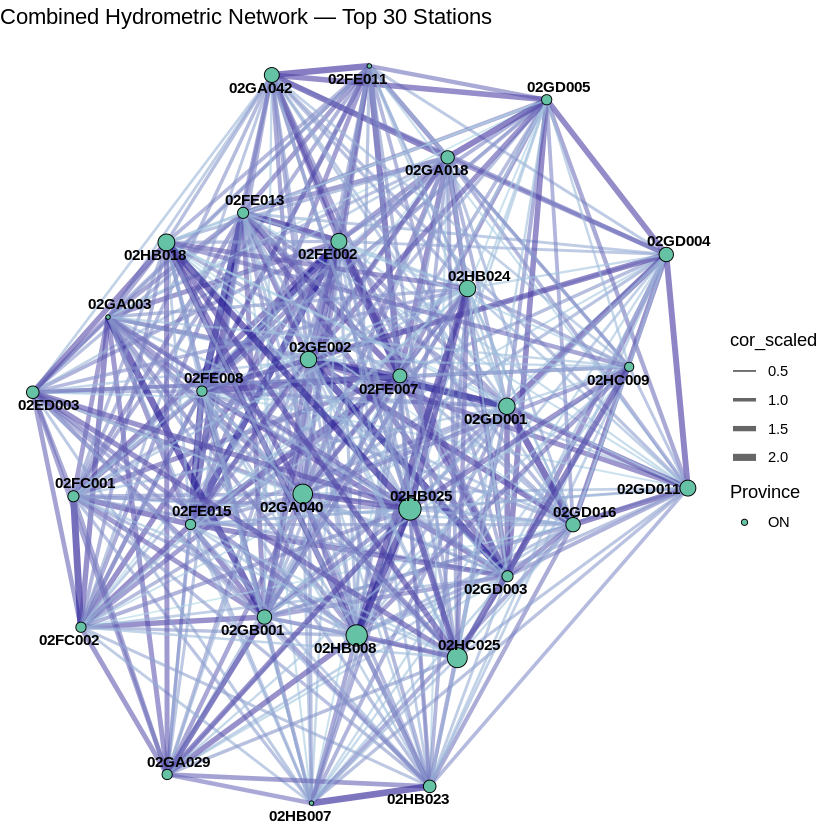

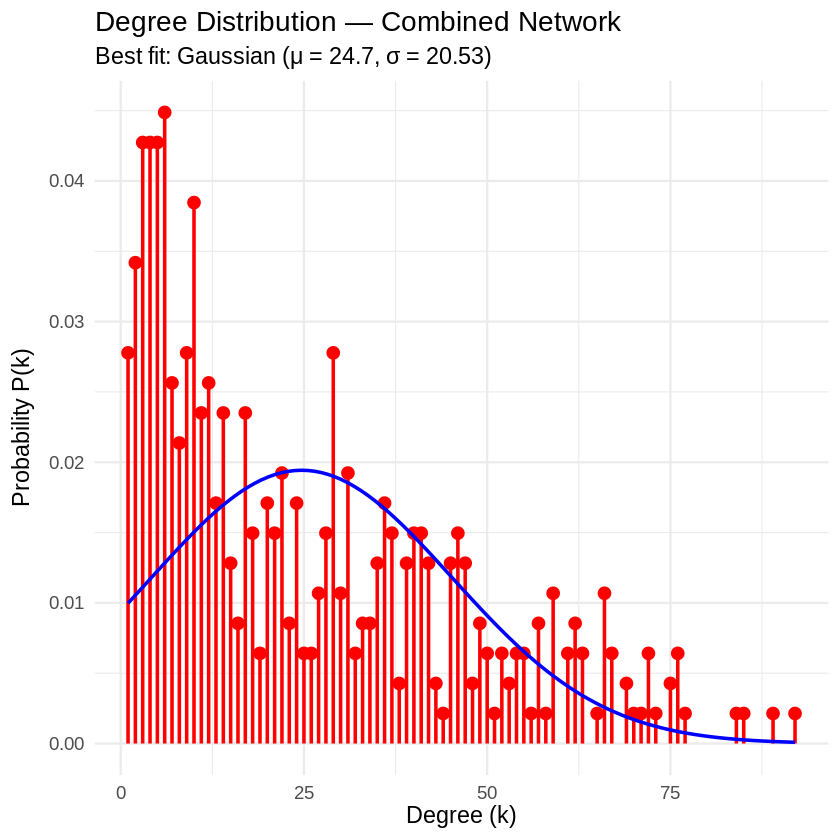

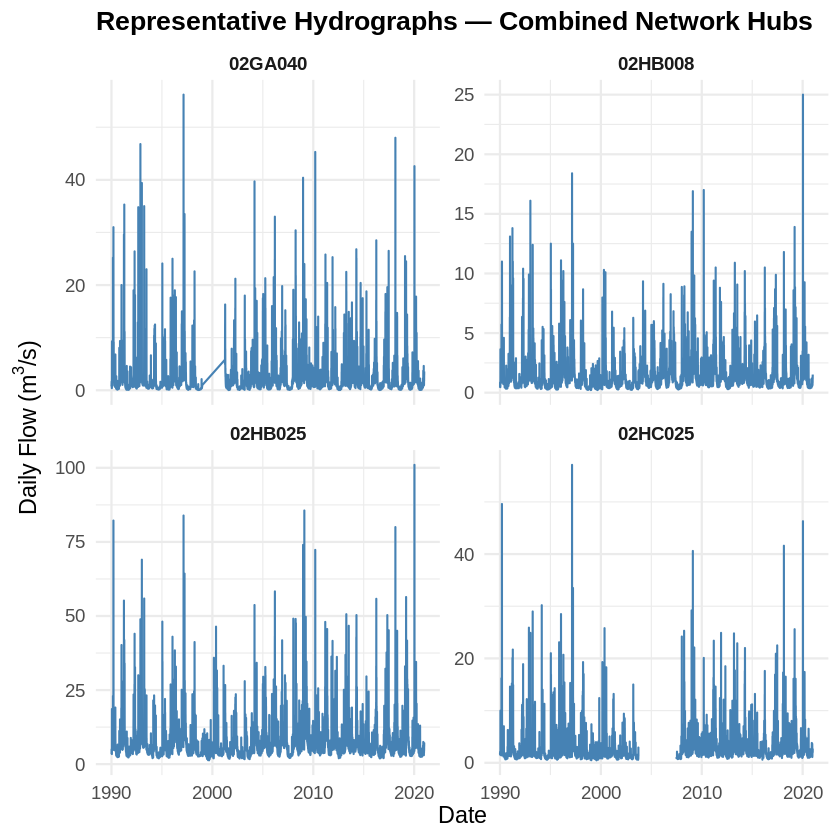

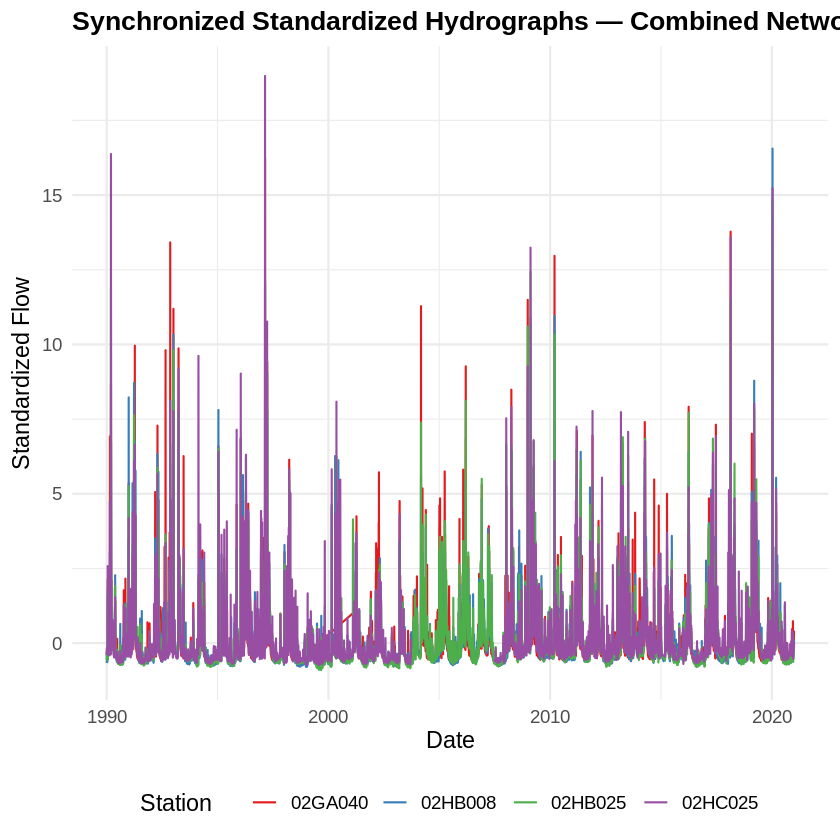

# A tibble: 47 × 6
   station province degree betweenness clustering community
   <chr>   <chr>     <dbl>       <dbl>      <dbl>     <dbl>
 1 02HB025 ON           92       2166.      0.498         4
 2 02HB008 ON           89       1884.      0.507         4
 3 02HC025 ON           85       1174.      0.519         4
 4 02GA040 ON           84        776.      0.555         4
 5 02HB018 ON           77        672.      0.563         4
 6 02GD001 ON           76        744.      0.553         4
 7 02GE002 ON           76        786.      0.568         4
 8 02HB024 ON           76        520.      0.574         4
 9 02FE002 ON           75        650.      0.605         4
10 02GD011 ON           75        434.      0.500         4
# ℹ 37 more rows


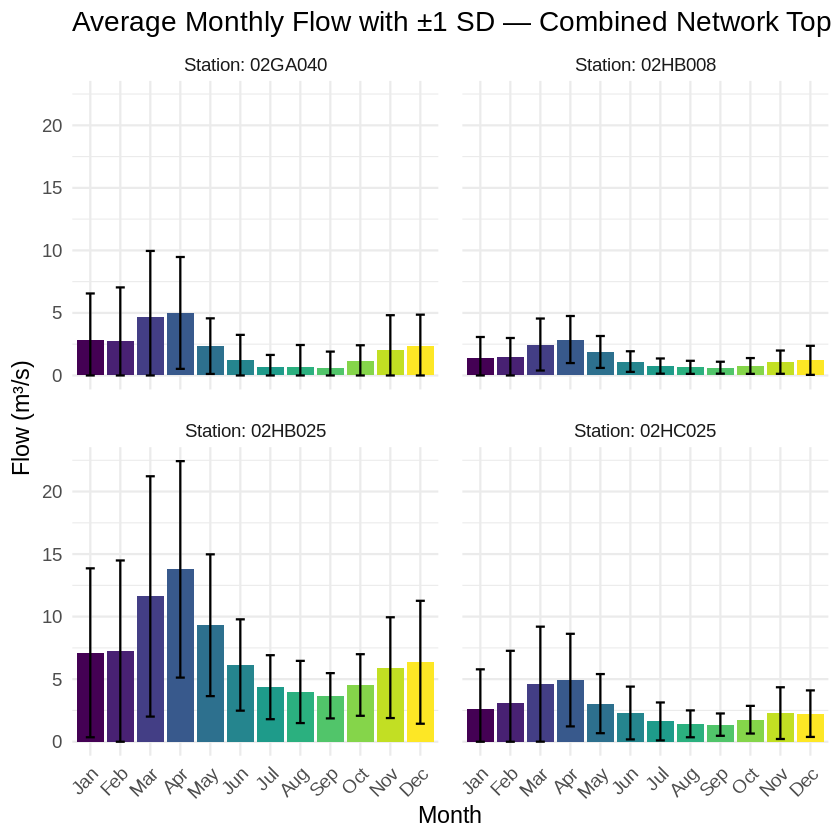

In [3]:
## =====================================================================
## COMBINED (REGIONAL) NETWORK ANALYSIS — Ontario + Quebec + Manitoba
##
## This script builds the transboundary/combined hydrometric network and
## reproduces, at the combined-network level, every analysis already run
## per-province (global metrics, node-level metrics, hub identification,
## community detection, representative hydrographs, monthly-flow figures).
##
## Section 1 needs, for each province, a station table (stations_XX_daily)
## and a daily-flow table (flow_XX_final). It gets them via three tiers,
## cheapest first, so you do NOT need to have to have re-run the provincial
## scripts in this same session:
##   Tier 1 - already in memory (stations_ON_daily / flow_ON_final, etc.)
##   Tier 2 - re-derived from a previously exported *_node_metrics.csv
##            (that file's "station" column tells us exactly which
##            stations passed the 25-year / 80%-completeness filter, so
##            we only need to re-download flows for that station list)
##   Tier 3 - full from-scratch rebuild: pull the province's station list
##            from HYDAT and re-apply the same 25-year / 80%-completeness
##            filter used in the original provincial scripts
## Edit PROVINCE_CONFIG below if your exported CSVs use different names
## or live in a different folder.
## =====================================================================

install.packages('tidyverse')
library(tidyverse)
install.packages('tidyhydat') # Install tidyhydat package
library(tidyhydat)
install.packages('igraph') # Install igraph package
library(igraph)
install.packages('ggraph')
library(ggraph)
install.packages('RColorBrewer')
library(RColorBrewer)
install.packages('scales')
library(scales)
install.packages(c('fitdistrplus', 'viridis', 'lubridate')) # Corrected: Install multiple packages by passing them as a character vector
library(fitdistrplus)
library(viridis)
library(lubridate)
install.packages('svglite') # Install svglite package for SVG output
library(svglite)

set.seed(2024)  # reproducibility for the random-graph null models below

# Run once to download the HYDAT database
download_hydat(ask = FALSE)

# -----------------------------------------------------------------------
# WHAT CHANGED FROM THE ORIGINAL "combined" SCRIPT, AND WHY
# -----------------------------------------------------------------------
# 1. The combined network is now built from a FRESH station x station
#    correlation matrix spanning all three provinces (Section 2), not
#    from unioning the three provincial edge lists. The provincial edge
#    lists only ever contained *within*-province pairs by construction
#    (each was derived from a correlation matrix computed on that
#    province's stations alone), so simply rbind-ing them can never
#    produce a single cross-province edge. Because WSC station codes
#    don't collide across provinces, the old approach would have
#    produced a "combined" graph that is really just three untouched,
#    disconnected provincial graphs sitting side by side — the opposite
#    of a transboundary network. Recomputing correlations across the
#    full combined station set is the only way to actually capture
#    inter-provincial synchronization, which is what the Methodology
#    section describes ("retaining all inter-provincial correlations
#    above the threshold").
# 2. `colnames(edges_ontario) <- c("from","to")` was applied to a
#    3-column data frame (station1, station2, correlation) — that's a
#    length-mismatch that errors in base R. Even if patched, it also
#    discarded the correlation/weight column, which we need for the
#    edge-strength summaries reported elsewhere in the manuscript
#    (mean r, max r, etc.).
# 3. Node-level metrics (degree, betweenness, clustering, hub flag,
#    Louvain community), a hub table, representative hydrographs, and
#    monthly-flow figures are now computed for the combined network —
#    previously only a handful of global scalars and a base-R histogram
#    were produced, with no parity to the provincial sections.
# 4. Each node now carries a PROVINCE attribute, enabling two diagnostics
#    that are central to a "transboundary system" framing but were
#    entirely absent before: the fraction of edges that cross a
#    provincial boundary, and whether Louvain communities stay within one
#    province or mix stations from several.
# 5. The small-world null model now uses a fixed seed and is wired into
#    a single, exported summary table (previously the n_sim = 50 loop's
#    results were computed but never merged into any output).
# 6. Hardcoded absolute Windows paths are gone; edges are rebuilt from
#    the in-memory flow data rather than round-tripped through CSVs of a
#    specific machine's file system. g_combined was also being built
#    twice in the original script (Steps 2 and 3) — that redundancy is
#    removed.
# 7. Section 1 no longer just assumes the provincial objects are sitting
#    in memory (stopifnot() alone would abort the whole script the
#    moment that's not true, e.g. after restarting R). It now falls back
#    to disk, and then to HYDAT, automatically.
# -----------------------------------------------------------------------


# =========================================================================
# 1. Assemble combined station metadata and daily-flow records
# =========================================================================

start_date <- as.Date("1990-01-01")
end_date    <- as.Date("2020-12-31")
min_years        <- 25
min_completeness <- 0.8

# Edit these to match the CSV names your provincial scripts actually wrote.
# (The Manitoba entry defaults to "Manito_..." to match the
# "Manito_edges.csv" naming already used in the original combined script.)
PROVINCE_CONFIG <- list(
  ON = list(prov_code = "ON", node_metrics_csv = "ON_node_metrics.csv"),
  QC = list(prov_code = "QC", node_metrics_csv = "QC_node_metrics.csv"),
  MB = list(prov_code = "MB", node_metrics_csv = "Manito_node_metrics.csv")
)

get_daily_flows <- function(station_ids, start_date, end_date) {
  purrr::map_dfr(station_ids, function(id) {
    message("  Downloading: ", id)
    hy_daily_flows(station_number = id) %>%
      dplyr::filter(Date >= start_date, Date <= end_date) %>%
      dplyr::select(STATION_NUMBER, Date, Value)
  })
}

# Tier 3 helper: rebuild a province's station list + flows entirely from
# HYDAT, re-applying the same quality filter as the original scripts.
build_province_from_scratch <- function(prov_code) {
  message(prov_code, ": no in-memory objects and no node-metrics CSV found — ",
          "rebuilding from HYDAT from scratch (this re-downloads everything ",
          "and will take a while).")

  stations_prov_all <- hy_stations() %>%
    dplyr::filter(PROV_TERR_STATE_LOC == prov_code) %>%
    dplyr::select(STATION_NUMBER, STATION_NAME, LATITUDE, LONGITUDE, DRAINAGE_AREA_GROSS)

  daily_available <- hy_daily_flows() %>% dplyr::distinct(STATION_NUMBER)

  stations_prov_daily <- stations_prov_all %>%
    dplyr::semi_join(daily_available, by = "STATION_NUMBER")

  flow_prov_raw <- get_daily_flows(stations_prov_daily$STATION_NUMBER, start_date, end_date)

  valid_prov <- flow_prov_raw %>%
    dplyr::mutate(year = lubridate::year(Date)) %>%
    dplyr::group_by(STATION_NUMBER) %>%
    dplyr::summarise(
      n_years = dplyr::n_distinct(year),
      completeness = mean(!is.na(Value)),
      .groups = "drop"
    ) %>%
    dplyr::filter(n_years >= min_years, completeness >= min_completeness) %>%
    dplyr::pull(STATION_NUMBER)

  list(
    stations = stations_prov_daily %>% dplyr::filter(STATION_NUMBER %in% valid_prov),
    flow     = flow_prov_raw %>% dplyr::filter(STATION_NUMBER %in% valid_prov) %>%
      dplyr::arrange(STATION_NUMBER, Date)
  )
}

# Tier 1 + Tier 2 + Tier 3 dispatcher for one province
load_province <- function(cfg) {

  stations_obj <- paste0("stations_", cfg$prov_code, "_daily")
  flow_obj     <- paste0("flow_", cfg$prov_code, "_final")

  # Tier 1: already in memory
  if (exists(stations_obj, inherits = TRUE) && exists(flow_obj, inherits = TRUE)) {
    message(cfg$prov_code, ": using objects already in memory")
    return(list(stations = get(stations_obj), flow = get(flow_obj)))
  }

  # Tier 2: previously exported node-metrics CSV tells us the valid station list
  if (file.exists(cfg$node_metrics_csv)) {
    message(cfg$prov_code, ": re-deriving from ", cfg$node_metrics_csv,
            " (re-downloading flows for the stations listed there)")

    valid_stations <- read.csv(cfg$node_metrics_csv, stringsAsFactors = FALSE)$station
    stopifnot(length(valid_stations) > 0)

    stations_prov <- hy_stations() %>%
      dplyr::filter(STATION_NUMBER %in% valid_stations) %>%
      dplyr::select(STATION_NUMBER, STATION_NAME, LATITUDE, LONGITUDE, DRAINAGE_AREA_GROSS)

    flow_prov <- get_daily_flows(valid_stations, start_date, end_date)

    return(list(stations = stations_prov, flow = flow_prov))
  }

  # Tier 3: nothing saved at all — rebuild from scratch
  build_province_from_scratch(cfg$prov_code)
}

on_data <- load_province(PROVINCE_CONFIG$ON)
qc_data <- load_province(PROVINCE_CONFIG$QC)
mb_data <- load_province(PROVINCE_CONFIG$MB)

stations_ON_daily <- on_data$stations; flow_ON_final <- on_data$flow
stations_QC_daily <- qc_data$stations; flow_QC_final <- qc_data$flow
stations_MB_daily <- mb_data$stations; flow_MB_final <- mb_data$flow

stations_all <- bind_rows(
  stations_ON_daily %>% mutate(PROVINCE = "ON"),
  stations_QC_daily %>% mutate(PROVINCE = "QC"),
  stations_MB_daily %>% mutate(PROVINCE = "MB")
)

# WSC station numbers are unique nationally, but check rather than assume
stopifnot(!any(duplicated(stations_all$STATION_NUMBER)))

flow_all <- bind_rows(
  flow_ON_final %>% mutate(PROVINCE = "ON"),
  flow_QC_final %>% mutate(PROVINCE = "QC"),
  flow_MB_final %>% mutate(PROVINCE = "MB")
)

n_stations_total <- n_distinct(flow_all$STATION_NUMBER)
n_stations_total  # total stations entering the combined network


# =========================================================================
# 2. Recompute the FULL correlation matrix across all three provinces
# =========================================================================

flow_wide_all <- flow_all %>%
  dplyr::select(STATION_NUMBER, Date, Value) %>%
  pivot_wider(names_from = STATION_NUMBER, values_from = Value)

cor_matrix_all <- cor(flow_wide_all %>% dplyr::select(-Date),
                       use = "pairwise.complete.obs")

threshold <- 0.7
cor_matrix_all[lower.tri(cor_matrix_all, diag = TRUE)] <- NA

edges_df_all <- as.data.frame(as.table(cor_matrix_all)) %>%
  dplyr::rename(station1 = Var1, station2 = Var2, correlation = Freq) %>%
  dplyr::filter(!is.na(correlation), correlation >= threshold) %>%
  dplyr::mutate(station1 = as.character(station1),
                station2 = as.character(station2))

nrow(edges_df_all)

# Tag each edge as within-province or cross-province
province_lookup <- setNames(stations_all$PROVINCE, stations_all$STATION_NUMBER)

edges_df_all <- edges_df_all %>%
  mutate(
    province1 = province_lookup[station1],
    province2 = province_lookup[station2],
    edge_type = if_else(province1 == province2, "within-province", "cross-province")
  )

table(edges_df_all$edge_type)
mean(edges_df_all$correlation)
max(edges_df_all$correlation)


# =========================================================================
# 3. Build the combined graph
# =========================================================================

g_all <- graph_from_data_frame(
  edges_df_all %>% dplyr::select(station1, station2, correlation, edge_type),
  directed  = FALSE,
  vertices  = stations_all %>% dplyr::select(STATION_NUMBER, PROVINCE) %>% distinct()
)

E(g_all)$weight <- E(g_all)$correlation   # kept for optional weighted analyses (Section 5 note)

vcount(g_all)                       # total stations (including any with no qualifying edge)
ecount(g_all)                       # total edges (within- + cross-province)
sum(degree(g_all) > 0)              # stations that formed at least one connection


# =========================================================================
# 4. Connected components / fragmentation
# =========================================================================

comp <- components(g_all)
cat("Number of components:", comp$no, "\n")
cat("Giant component size:", max(comp$csize), "of", vcount(g_all), "stations\n")

giant_nodes <- V(g_all)[comp$membership == which.max(comp$csize)]
g_giant <- induced_subgraph(g_all, giant_nodes)

fragmentation_index     <- 1 - (max(comp$csize) / vcount(g_all))
largest_component_ratio <- max(comp$csize) / vcount(g_all)

component_sizes <- tibble(component = seq_len(comp$no), size = comp$csize) %>%
  arrange(desc(size))

# Provincial makeup of the giant component vs. the rest
table(V(g_giant)$PROVINCE)


# =========================================================================
# 5. Node-level metrics (computed on the giant component)
# =========================================================================
# NOTE ON WEIGHTS: to stay directly comparable with the Manitoba, Quebec,
# and Ontario sections already in the manuscript — whose betweenness,
# clustering, and Louvain calls were run on unweighted/topological graphs
# (their edge attribute was named "correlation", not "weight", so igraph
# never auto-applied it) — betweenness, clustering, and community
# detection below are also computed unweighted (weights = NA). If you'd
# rather make the whole paper consistent with the "weighted networks"
# language in the Methodology section, switch weights = NA to
# weights = E(g_giant)$weight throughout this section AND re-run the
# three provincial scripts the same way, since that would change their
# previously reported numbers too.

node_metrics_all <- tibble(
  station     = V(g_giant)$name,
  province    = V(g_giant)$PROVINCE,
  degree      = degree(g_giant),
  betweenness = betweenness(g_giant, weights = NA),
  clustering  = transitivity(g_giant, type = "local", vids = V(g_giant)),
  hub         = degree(g_giant) > quantile(degree(g_giant), 0.9)
)

node_metrics_all$community <- cluster_louvain(g_giant, weights = NA)$membership

# Explicitly add degree and community as vertex attributes to g_giant
V(g_giant)$degree    <- node_metrics_all$degree[match(V(g_giant)$name, node_metrics_all$station)]
V(g_giant)$community <- node_metrics_all$community[match(V(g_giant)$name, node_metrics_all$station)]


# =========================================================================
# 6. Global metrics
# =========================================================================

total_nodes     <- vcount(g_giant)
total_edges     <- ecount(g_giant)
density         <- edge_density(g_giant)
avg_degree      <- mean(node_metrics_all$degree)
max_degree      <- max(node_metrics_all$degree)
avg_betweenness <- mean(node_metrics_all$betweenness)
avg_clustering  <- transitivity(g_giant, type = "global")
avg_path_length <- mean_distance(g_giant)

# Small-world index against a matched Erdos-Renyi null (averaged over draws)
n_sim <- 50
Crand <- numeric(n_sim)
Lrand <- numeric(n_sim)

for (i in seq_len(n_sim)) {
  g_rand      <- sample_gnp(n = total_nodes, p = density, directed = FALSE)
  g_rand      <- simplify(g_rand)
  comp_rand   <- components(g_rand)
  rand_giant  <- induced_subgraph(g_rand, V(g_rand)[comp_rand$membership == which.max(comp$csize)])
  Crand[i]    <- transitivity(rand_giant, type = "average")
  Lrand[i]    <- mean_distance(rand_giant)
}

C_rand_mean <- mean(Crand, na.rm = TRUE)
L_rand_mean <- mean(Lrand, na.rm = TRUE)

smallworld_index <- (avg_clustering / C_rand_mean) / (avg_path_length / L_rand_mean)

cross_province_edge_fraction <- mean(edges_df_all$edge_type == "cross-province")

global_metrics_all <- tibble(
  total_nodes, total_edges, density, avg_degree, max_degree,
  avg_betweenness, avg_clustering, avg_path_length, smallworld_index,
  fragmentation_index, largest_component_ratio,
  cross_province_edge_fraction,
  mean_correlation = mean(edges_df_all$correlation),
  max_correlation  = max(edges_df_all$correlation)
)
print(as.data.frame(global_metrics_all))


# =========================================================================
# 7. Community sizes & provincial composition of each community
# =========================================================================

community_sizes_all <- node_metrics_all %>%
  count(community, name = "size") %>%
  arrange(desc(size))

community_province_mix <- node_metrics_all %>%
  count(community, province) %>%
  group_by(community) %>%
  mutate(community_size = sum(n), province_share = n / community_size) %>%
  ungroup() %>%
  arrange(desc(community_size), desc(province_share))

n_mixed_communities <- community_province_mix %>%
  group_by(community) %>%
  summarise(n_provinces = n_distinct(province), .groups = "drop") %>%
  filter(n_provinces > 1) %>%
  nrow()

cat(n_mixed_communities, "of", n_distinct(node_metrics_all$community),
    "communities span more than one province\n")


# =========================================================================
# 8. Network visualization — top N stations by degree, coloured by province
# =========================================================================

top_n <- 30
top_nodes <- node_metrics_all %>% arrange(desc(degree)) %>% slice(1:top_n) %>% pull(station)
sub_g <- induced_subgraph(g_giant, vids = top_nodes)

E(sub_g)$cor_scaled  <- rescale(E(sub_g)$correlation, to = c(0.5, 2))
V(sub_g)$size_scaled <- rescale(V(sub_g)$degree, to = c(4, 10))

p_network <- ggraph(sub_g, layout = "fr") +
  geom_edge_link(aes(width = cor_scaled, color = correlation), alpha = 0.6) +
  scale_edge_color_gradient(low = "lightblue", high = "darkblue") +
  geom_node_point(aes(size = size_scaled, shape = PROVINCE, fill = PROVINCE),
                  color = "black", stroke = 0.4) +
  scale_shape_manual(values = c(ON = 21, QC = 22, MB = 24)) +
  scale_fill_brewer(palette = "Set2") +
  geom_node_text(aes(label = name), repel = TRUE, fontface = "bold", size = 3.2) +
  ggtitle(paste0("Combined Hydrometric Network — Top ", top_n, " Stations")) +
  theme_void() +
  guides(edge_color = guide_colorbar(title = "Correlation"),
         size = "none",
         shape = guide_legend(title = "Province"),
         fill  = guide_legend(title = "Province")) +
  scale_edge_width(range = c(0.5, 2))

print(p_network)
ggsave("Combined_network_top30.svg", p_network, width = 10, height = 9)


# =========================================================================
# 9. Degree distribution & Gaussian/Poisson fit
# =========================================================================

degree_vals <- node_metrics_all$degree

degree_df <- tibble(k = degree_vals) %>%
  count(k, name = "n") %>%
  mutate(Pk = n / sum(n))

fit_norm <- fitdist(degree_vals, "norm")
fit_pois <- fitdist(degree_vals, "pois")

model_comparison <- tibble(
  Model = c("Gaussian", "Poisson"),
  AIC   = c(AIC(fit_norm), AIC(fit_pois)),
  BIC   = c(BIC(fit_pois), BIC(fit_pois))
)
print(model_comparison)

best_model <- if (AIC(fit_norm) < AIC(fit_pois)) "Gaussian" else "Poisson"
mu     <- unname(fit_norm$estimate["mean"])
sigma  <- unname(fit_norm$estimate["sd"])
lambda <- unname(fit_pois$estimate["lambda"])

p_degree <- ggplot(degree_df, aes(x = k, y = Pk)) +
  geom_segment(aes(xend = k, y = 0, yend = Pk), color = "red", linewidth = 1) +
  geom_point(color = "red", size = 3) +
  theme_minimal(base_size = 14) +
  labs(title = "Degree Distribution — Combined Network",
       x = "Degree (k)", y = "Probability P(k)")

if (best_model == "Gaussian") {
  p_degree <- p_degree +
    stat_function(fun = function(x) dnorm(x, mean = mu, sd = sigma),
                  color = "blue", linewidth = 1) +
    labs(subtitle = paste0("Best fit: Gaussian (μ = ", round(mu, 2),
                            ", σ = ", round(sigma, 2), ")"))
} else {
  p_degree <- p_degree +
    stat_function(fun = function(x) dpois(x, lambda = lambda),
                  color = "blue", linewidth = 1) +
    labs(subtitle = paste0("Best fit: Poisson (λ = ", round(lambda, 2), ")"))
}

print(p_degree)
ggsave("Combined_degree_distribution.svg", p_degree, width = 8, height = 5)


# =========================================================================
# 10. Representative hydrographs — top 4 hubs (combined network)
# =========================================================================

hub_stations_all <- node_metrics_all %>%
  filter(hub) %>%
  arrange(desc(degree)) %>%
  slice(1:4) %>%
  pull(station)

hub_flows_all <- flow_all %>% filter(STATION_NUMBER %in% hub_stations_all)

p_hydrographs <- ggplot(hub_flows_all, aes(x = Date, y = Value)) +
  geom_line(color = "steelblue", linewidth = 0.6) +
  facet_wrap(~ STATION_NUMBER, ncol = 2, scales = "free_y") +
  labs(title = "Representative Hydrographs — Combined Network Hubs",
       x = "Date", y = expression("Daily Flow (m"^3*"/s)")) +
  theme_minimal(base_size = 14) +
  theme(plot.title = element_text(face = "bold", size = 16),
        strip.text = element_text(face = "bold"))

print(p_hydrographs)
ggsave("Combined_hub_hydrographs_2x2.png", p_hydrographs, width = 12, height = 8)

# Standardized, synchronized hydrographs (all four overlaid on one panel)
hub_flows_std_all <- hub_flows_all %>%
  group_by(STATION_NUMBER) %>%
  mutate(flow_std = (Value - mean(Value, na.rm = TRUE)) / sd(Value, na.rm = TRUE)) %>%
  ungroup()

p_std <- ggplot(hub_flows_std_all, aes(x = Date, y = flow_std, color = STATION_NUMBER)) +
  geom_line(linewidth = 0.6) +
  labs(title = "Synchronized Standardized Hydrographs — Combined Network Hubs",
       x = "Date", y = "Standardized Flow", color = "Station") +
  scale_color_brewer(palette = "Set1") +
  theme_minimal(base_size = 14) +
  theme(plot.title = element_text(face = "bold", size = 16), legend.position = "bottom")

print(p_std)
ggsave("Combined_hub_hydrographs_standardized.svg", p_std, width = 12, height = 6)


# =========================================================================
# 11. Average monthly flow (+/- 1 SD) — top 4 hubs (combined network)
# =========================================================================

monthly_stats_top4_all <- hub_flows_all %>%
  mutate(Month = month(Date, label = TRUE, abbr = TRUE)) %>%
  group_by(STATION_NUMBER, Month) %>%
  summarise(AvgFlow = mean(Value, na.rm = TRUE),
            SDFlow  = sd(Value, na.rm = TRUE),
            .groups = "drop")

p_monthly_sd <- ggplot(monthly_stats_top4_all, aes(x = Month, y = AvgFlow, fill = Month)) +
  geom_col(show.legend = FALSE) +
  geom_errorbar(aes(ymin = pmax(AvgFlow - SDFlow, 0), ymax = AvgFlow + SDFlow),
                width = 0.3, color = "black") +
  facet_wrap(~ STATION_NUMBER, ncol = 2,
             labeller = labeller(STATION_NUMBER = function(x) paste("Station:", x))) +
  scale_fill_viridis_d() +
  theme_minimal(base_size = 14) +
  labs(title = "Average Monthly Flow with ±1 SD — Combined Network Top 4 Hubs",
       x = "Month", y = "Flow (m³/s)") +
  theme(panel.spacing = unit(1, "lines"),
        axis.text.x = element_text(angle = 45, hjust = 1))

print(p_monthly_sd)
ggsave("Combined_monthlySD.svg", p_monthly_sd, width = 10, height = 7)


# =========================================================================
# 12. Hub table (mirrors Tables 2-4 in the manuscript)
# =========================================================================

hub_table_all <- node_metrics_all %>%
  filter(hub) %>%
  arrange(desc(degree)) %>%
  dplyr::select(station, province, degree, betweenness, clustering, community)

print(hub_table_all)


# =========================================================================
# 13. Export combined-network outputs
# =========================================================================

write.csv(node_metrics_all,       "Combined_node_metrics.csv",           row.names = FALSE)
write.csv(hub_table_all,          "Combined_hub_table.csv",              row.names = FALSE)
write.csv(community_sizes_all,    "Combined_community_sizes.csv",        row.names = FALSE)
write.csv(community_province_mix, "Combined_community_province_mix.csv", row.names = FALSE)
write.csv(edges_df_all,           "Combined_edges.csv",                  row.names = FALSE)
write.csv(global_metrics_all,     "Combined_global_metrics.csv",         row.names = FALSE)
write.csv(component_sizes,        "Combined_component_sizes.csv",        row.names = FALSE)

In [5]:
RESULTS_DIR <- "/content/"
list.files(RESULTS_DIR, full.names = TRUE)

[1] "/content//Combined_community_province_mix.csv"      
 [2] "/content//Combined_community_sizes.csv"             
 [3] "/content//Combined_component_sizes.csv"             
 [4] "/content//Combined_degree_distribution.svg"         
 [5] "/content//Combined_edges.csv"                       
 [6] "/content//Combined_global_metrics.csv"              
 [7] "/content//Combined_hub_hydrographs_2x2.png"         
 [8] "/content//Combined_hub_hydrographs_standardized.svg"
 [9] "/content//Combined_hub_table.csv"                   
[10] "/content//Combined_monthlySD.svg"                   
[11] "/content//Combined_network_top30.svg"               
[12] "/content//Combined_node_metrics.csv"                
[13] "/content//sample_data"

In [7]:
## =====================================================================
## 00_setup.R — run this once per Colab session, then run 01-05 in order
## (or jump straight to whichever stage you need; each one auto-sources
## this file if you haven't already).
##
## CHANGED FROM THE EARLIER VERSION OF THIS FILE: that version pointed
## install.packages() at Posit's precompiled binary repo
## (packagemanager.posit.co) to install faster. If that binary snapshot
## doesn't exactly match Colab's current R build, install.packages() can
## hard-error and stop the whole script -- which is almost certainly why
## "setup.R wouldn't work." This version installs from plain CRAN like
## your working script did: slower (a couple of minutes instead of
## seconds), but it's what's actually been confirmed to run.
## =====================================================================

required_pkgs <- c("tidyverse", "tidyhydat", "igraph", "ggraph",
                    "RColorBrewer", "scales", "fitdistrplus", "viridis",
                    "lubridate", "svglite")

new_pkgs <- setdiff(required_pkgs, rownames(installed.packages()))
if (length(new_pkgs) > 0) install.packages(new_pkgs)

invisible(lapply(required_pkgs, library, character.only = TRUE))
library(parallel)

set.seed(2024)

N_CORES <- max(1, parallel::detectCores() - 1)
message("Using ", N_CORES, " core(s) for parallel steps")

# ---- Study period / quality filter (used by 01_load_data.R) ----------
start_date       <- as.Date("1990-01-01")
end_date         <- as.Date("2020-12-31")
min_years        <- 25
min_completeness <- 0.8

# Edit these to match the CSV names your provincial scripts actually
# wrote, if you have them (used as a Tier-2 fallback in 01_load_data.R).
PROVINCE_CONFIG <- list(
  ON = list(prov_code = "ON", node_metrics_csv = "ON_node_metrics.csv"),
  QC = list(prov_code = "QC", node_metrics_csv = "QC_node_metrics.csv"),
  MB = list(prov_code = "MB", node_metrics_csv = "Manito_node_metrics.csv")
)

# ---- Optional Google Drive cache --------------------------------------
USE_DRIVE_CACHE   <- dir.exists("/content/drive/MyDrive")
DRIVE_CACHE_DIR   <- "/content/drive/MyDrive/hydro_network_cache"
DRIVE_RESULTS_DIR <- "/content/drive/MyDrive/hydro_network_results"

if (USE_DRIVE_CACHE) {
  dir.create(DRIVE_CACHE_DIR, showWarnings = FALSE, recursive = TRUE)
  dir.create(DRIVE_RESULTS_DIR, showWarnings = FALSE, recursive = TRUE)
  RESULTS_DIR <- DRIVE_RESULTS_DIR
  message("Google Drive detected — caching to ", DRIVE_CACHE_DIR,
          " and saving outputs to ", DRIVE_RESULTS_DIR)
} else {
  RESULTS_DIR <- "Combined_network_outputs"
  dir.create(RESULTS_DIR, showWarnings = FALSE, recursive = TRUE)
  message("Google Drive not mounted — nothing will persist past this ",
          "session. Mount Drive (folder icon in the left sidebar -> ",
          "Mount Drive) before running 01_load_data.R if you want to ",
          "avoid re-downloading HYDAT and re-running stages next time.")
}

cache_path  <- function(name) {
  if (USE_DRIVE_CACHE) file.path(DRIVE_CACHE_DIR, name) else file.path(tempdir(), name)
}
result_path <- function(name) file.path(RESULTS_DIR, name)

# ---- HYDAT database: restore from Drive cache, or download once -------
# Wrapped in tryCatch so a problem with the Drive copy (e.g. Drive not
# fully synced yet) falls back to a fresh download instead of stopping
# the script -- this is the other place the earlier version could have
# hard-failed.
local_hydat_dir  <- tidyhydat::hy_dir()
local_hydat_file <- file.path(local_hydat_dir, "Hydat.sqlite3")

if (USE_DRIVE_CACHE) {
  hydat_cache_file <- file.path(DRIVE_CACHE_DIR, "Hydat.sqlite3")
  if (file.exists(hydat_cache_file) && !file.exists(local_hydat_file)) {
    message("Restoring cached HYDAT database from Drive...")
    tryCatch({
      dir.create(local_hydat_dir, showWarnings = FALSE, recursive = TRUE)
      file.copy(hydat_cache_file, local_hydat_file)
    }, error = function(e) {
      message("Couldn't restore from Drive (", conditionMessage(e), ") — will download instead.")
    })
  }
}

if (!file.exists(local_hydat_file)) {
  message("Downloading HYDAT database (one-time; several minutes)...")
  tidyhydat::download_hydat(ask = FALSE)
  if (USE_DRIVE_CACHE) {
    message("Caching HYDAT database to Drive so this never has to happen again...")
    tryCatch(
      file.copy(local_hydat_file, file.path(DRIVE_CACHE_DIR, "Hydat.sqlite3"), overwrite = TRUE),
      error = function(e) message("Couldn't cache to Drive (", conditionMessage(e), ") — not fatal, continuing.")
    )
  }
} else {
  message("HYDAT database already present — no download needed.")
}

message("Setup complete. RESULTS_DIR = ", RESULTS_DIR)

Using 7 core(s) for parallel steps

Google Drive not mounted — nothing will persist past this session. Mount Drive (folder icon in the left sidebar -> Mount Drive) before running 01_load_data.R if you want to avoid re-downloading HYDAT and re-running stages next time.

HYDAT database already present — no download needed.

Setup complete. RESULTS_DIR = Combined_network_outputs



In [8]:
## =====================================================================
## 01_load_data.R
## Depends on: 00_setup.R (auto-sourced below if needed)
## Produces:   stations_all, flow_all   (in memory + cached as
##             stations_flow_all.rds so future sessions can skip this
##             stage entirely)
## =====================================================================

if (!exists("USE_DRIVE_CACHE")) {
  message("00_setup.R hasn't been run yet in this session — sourcing it now...")
  source("00_setup.R")
}

combined_cache_file <- cache_path("stations_flow_all.rds")

if (file.exists(combined_cache_file)) {
  message("Loading cached combined station/flow tables (skipping HYDAT download)...")
  cached <- readRDS(combined_cache_file)
  stations_all <- cached$stations_all
  flow_all     <- cached$flow_all

} else {

  # hy_daily_flows() accepts a whole vector of station numbers and does
  # ONE local SQLite query -- much faster than the original per-station loop.
  get_daily_flows <- function(station_ids, start_date, end_date) {
    hy_daily_flows(station_number = station_ids) %>%
      dplyr::filter(Date >= start_date, Date <= end_date) %>%
      dplyr::select(STATION_NUMBER, Date, Value)
  }

  # Tier 3 helper: rebuild a province's station list + flows entirely from
  # HYDAT, re-applying the same quality filter as the original scripts.
  build_province_from_scratch <- function(prov_code) {
    message(prov_code, ": no in-memory objects and no node-metrics CSV found — ",
            "rebuilding from HYDAT from scratch.")

    stations_prov_all <- hy_stations() %>%
      dplyr::filter(PROV_TERR_STATE_LOC == prov_code) %>%
      dplyr::select(STATION_NUMBER, STATION_NAME, LATITUDE, LONGITUDE, DRAINAGE_AREA_GROSS)

    daily_available <- hy_daily_flows() %>% dplyr::distinct(STATION_NUMBER)

    stations_prov_daily <- stations_prov_all %>%
      dplyr::semi_join(daily_available, by = "STATION_NUMBER")

    flow_prov_raw <- get_daily_flows(stations_prov_daily$STATION_NUMBER, start_date, end_date)

    valid_prov <- flow_prov_raw %>%
      dplyr::mutate(year = lubridate::year(Date)) %>%
      dplyr::group_by(STATION_NUMBER) %>%
      dplyr::summarise(
        n_years = dplyr::n_distinct(year),
        completeness = mean(!is.na(Value)),
        .groups = "drop"
      ) %>%
      dplyr::filter(n_years >= min_years, completeness >= min_completeness) %>%
      dplyr::pull(STATION_NUMBER)

    list(
      stations = stations_prov_daily %>% dplyr::filter(STATION_NUMBER %in% valid_prov),
      flow     = flow_prov_raw %>% dplyr::filter(STATION_NUMBER %in% valid_prov) %>%
        dplyr::arrange(STATION_NUMBER, Date)
    )
  }

  # Tier 1 (memory) -> Tier 2 (previous node-metrics CSV) -> Tier 3 (scratch)
  load_province <- function(cfg) {

    stations_obj <- paste0("stations_", cfg$prov_code, "_daily")
    flow_obj     <- paste0("flow_", cfg$prov_code, "_final")

    if (exists(stations_obj, inherits = TRUE) && exists(flow_obj, inherits = TRUE)) {
      message(cfg$prov_code, ": using objects already in memory")
      return(list(stations = get(stations_obj), flow = get(flow_obj)))
    }

    if (file.exists(cfg$node_metrics_csv)) {
      message(cfg$prov_code, ": re-deriving from ", cfg$node_metrics_csv,
              " (one batched HYDAT query for all listed stations)")

      valid_stations <- read.csv(cfg$node_metrics_csv, stringsAsFactors = FALSE)$station
      stopifnot(length(valid_stations) > 0)

      stations_prov <- hy_stations() %>%
        dplyr::filter(STATION_NUMBER %in% valid_stations) %>%
        dplyr::select(STATION_NUMBER, STATION_NAME, LATITUDE, LONGITUDE, DRAINAGE_AREA_GROSS)

      flow_prov <- get_daily_flows(valid_stations, start_date, end_date)

      return(list(stations = stations_prov, flow = flow_prov))
    }

    build_province_from_scratch(cfg$prov_code)
  }

  on_data <- load_province(PROVINCE_CONFIG$ON)
  qc_data <- load_province(PROVINCE_CONFIG$QC)
  mb_data <- load_province(PROVINCE_CONFIG$MB)

  stations_ON_daily <- on_data$stations; flow_ON_final <- on_data$flow
  stations_QC_daily <- qc_data$stations; flow_QC_final <- qc_data$flow
  stations_MB_daily <- mb_data$stations; flow_MB_final <- mb_data$flow

  stations_all <- bind_rows(
    stations_ON_daily %>% mutate(PROVINCE = "ON"),
    stations_QC_daily %>% mutate(PROVINCE = "QC"),
    stations_MB_daily %>% mutate(PROVINCE = "MB")
  )

  # WSC station numbers are unique nationally, but check rather than assume
  stopifnot(!any(duplicated(stations_all$STATION_NUMBER)))

  flow_all <- bind_rows(
    flow_ON_final %>% mutate(PROVINCE = "ON"),
    flow_QC_final %>% mutate(PROVINCE = "QC"),
    flow_MB_final %>% mutate(PROVINCE = "MB")
  )

  saveRDS(list(stations_all = stations_all, flow_all = flow_all), combined_cache_file)
  message("Cached to ", combined_cache_file)
}

n_stations_total <- n_distinct(flow_all$STATION_NUMBER)
message(n_stations_total, " stations entering the combined network")

ON: using objects already in memory

QC: using objects already in memory

MB: using objects already in memory

Cached to /tmp/RtmpV9E3Fg/stations_flow_all.rds

518 stations entering the combined network



In [9]:
## =====================================================================
## 02_build_edges.R
## Depends on: 00_setup.R, 01_load_data.R (both auto-sourced if needed)
## Produces:   edges_df_all   (in memory + cached as edges_df_all.rds)
##
## Built from a FRESH station x station correlation matrix spanning ALL
## three provinces, not from unioning the three provincial edge lists
## (those only ever contain within-province pairs by construction, so
## simply rbind-ing them can never produce a cross-province edge).
## =====================================================================

if (!exists("USE_DRIVE_CACHE")) {
  message("00_setup.R hasn't been run yet in this session — sourcing it now...")
  source("00_setup.R")
}

if (!exists("stations_all") || !exists("flow_all")) {
  cached_data_file <- cache_path("stations_flow_all.rds")
  if (file.exists(cached_data_file)) {
    message("stations_all/flow_all not in memory — loading from cache...")
    cached <- readRDS(cached_data_file)
    stations_all <- cached$stations_all
    flow_all     <- cached$flow_all
  } else {
    message("stations_all/flow_all not found in memory or cache — running 01_load_data.R...")
    source("01_load_data.R")
  }
}

edges_cache_file <- cache_path("edges_df_all.rds")

if (file.exists(edges_cache_file)) {
  message("Loading cached combined edge list...")
  edges_df_all <- readRDS(edges_cache_file)

} else {

  flow_wide_all <- flow_all %>%
    dplyr::select(STATION_NUMBER, Date, Value) %>%
    pivot_wider(names_from = STATION_NUMBER, values_from = Value)

  cor_matrix_all <- cor(flow_wide_all %>% dplyr::select(-Date),
                         use = "pairwise.complete.obs")

  threshold <- 0.7
  cor_matrix_all[lower.tri(cor_matrix_all, diag = TRUE)] <- NA

  edges_df_all <- as.data.frame(as.table(cor_matrix_all)) %>%
    dplyr::rename(station1 = Var1, station2 = Var2, correlation = Freq) %>%
    dplyr::filter(!is.na(correlation), correlation >= threshold) %>%
    dplyr::mutate(station1 = as.character(station1),
                  station2 = as.character(station2))

  province_lookup <- setNames(stations_all$PROVINCE, stations_all$STATION_NUMBER)

  edges_df_all <- edges_df_all %>%
    mutate(
      province1 = province_lookup[station1],
      province2 = province_lookup[station2],
      edge_type = if_else(province1 == province2, "within-province", "cross-province")
    )

  saveRDS(edges_df_all, edges_cache_file)
  message("Cached to ", edges_cache_file)
}

message(nrow(edges_df_all), " edges total")
print(table(edges_df_all$edge_type))
message("mean r = ", round(mean(edges_df_all$correlation), 3),
        ", max r = ", round(max(edges_df_all$correlation), 3))

Cached to /tmp/RtmpV9E3Fg/edges_df_all.rds

5859 edges total




 cross-province within-province 
            375            5484 


mean r = 0.783, max r = 0.997



In [10]:
## =====================================================================
## 03_graph_and_metrics.R
## Depends on: 00_setup.R, 01_load_data.R, 02_build_edges.R (all
##             auto-sourced if needed)
## Produces:   g_giant, node_metrics_all, global_metrics_all,
##             community_sizes_all, community_province_mix,
##             component_sizes
##             (in memory + cached: g_giant.graphml plus one .rds each
##             for the tables below)
##
## This is the slowest stage to recompute from scratch (the n_sim = 50
## random-graph null model for the small-world index), so it's the one
## most worth checkpointing -- if you're only iterating on figures, you
## should never need to re-run this stage at all; 04_figures_and_exports.R
## will just load its cached outputs.
## =====================================================================

if (!exists("USE_DRIVE_CACHE")) {
  message("00_setup.R hasn't been run yet in this session — sourcing it now...")
  source("00_setup.R")
}

if (!exists("edges_df_all")) {
  cached_edges_file <- cache_path("edges_df_all.rds")
  if (file.exists(cached_edges_file)) {
    message("edges_df_all not in memory — loading from cache...")
    edges_df_all <- readRDS(cached_edges_file)
  } else {
    message("edges_df_all not found in memory or cache — running 02_build_edges.R...")
    source("02_build_edges.R")
  }
}

if (!exists("stations_all")) {
  cached_data_file <- cache_path("stations_flow_all.rds")
  stopifnot(file.exists(cached_data_file))  # 02_build_edges.R would have failed already otherwise
  stations_all <- readRDS(cached_data_file)$stations_all
}

graph_cache_file           <- cache_path("g_giant.graphml")
node_metrics_cache_file    <- cache_path("node_metrics_all.rds")
global_metrics_cache_file  <- cache_path("global_metrics_all.rds")
community_sizes_cache_file <- cache_path("community_sizes_all.rds")
community_mix_cache_file   <- cache_path("community_province_mix.rds")
component_sizes_cache_file <- cache_path("component_sizes.rds")

all_cached <- all(file.exists(graph_cache_file, node_metrics_cache_file,
                               global_metrics_cache_file, community_sizes_cache_file,
                               community_mix_cache_file, component_sizes_cache_file))

if (all_cached) {

  message("Loading cached graph and metrics (skipping rebuild + null-model simulation)...")
  g_giant                 <- read_graph(graph_cache_file, format = "graphml")
  node_metrics_all        <- readRDS(node_metrics_cache_file)
  global_metrics_all      <- readRDS(global_metrics_cache_file)
  community_sizes_all     <- readRDS(community_sizes_cache_file)
  community_province_mix  <- readRDS(community_mix_cache_file)
  component_sizes         <- readRDS(component_sizes_cache_file)

} else {

  # ---- Build the combined graph ----
  g_all <- graph_from_data_frame(
    edges_df_all %>% dplyr::select(station1, station2, correlation, edge_type),
    directed  = FALSE,
    vertices  = stations_all %>% dplyr::select(STATION_NUMBER, PROVINCE) %>% distinct()
  )
  E(g_all)$weight <- E(g_all)$correlation

  message(vcount(g_all), " total stations, ", ecount(g_all), " edges, ",
          sum(degree(g_all) > 0), " stations with at least one connection")

  # ---- Connected components / fragmentation ----
  comp <- components(g_all)
  message("Number of components: ", comp$no)
  message("Giant component size: ", max(comp$csize), " of ", vcount(g_all), " stations")

  giant_nodes <- V(g_all)[comp$membership == which.max(comp$csize)]
  g_giant <- induced_subgraph(g_all, giant_nodes)

  fragmentation_index     <- 1 - (max(comp$csize) / vcount(g_all))
  largest_component_ratio <- max(comp$csize) / vcount(g_all)

  component_sizes <- tibble(component = seq_len(comp$no), size = comp$csize) %>%
    arrange(desc(size))

  # ---- Node-level metrics ----
  # Unweighted (weights = NA) throughout, to stay comparable with the
  # Manitoba/Quebec/Ontario sections, whose betweenness/clustering/Louvain
  # calls never had a "weight"-named edge attribute for igraph to auto-apply.
  node_metrics_all <- tibble(
    station     = V(g_giant)$name,
    province    = V(g_giant)$PROVINCE,
    degree      = degree(g_giant),
    betweenness = betweenness(g_giant, weights = NA),
    clustering  = transitivity(g_giant, type = "local", vids = V(g_giant)),
    hub         = degree(g_giant) > quantile(degree(g_giant), 0.9)
  )
  node_metrics_all$community <- cluster_louvain(g_giant, weights = NA)$membership

  # Attach degree/community back onto the graph itself as real vertex
  # attributes so induced_subgraph() in 04_figures_and_exports.R carries
  # them through (a subgraph only inherits attributes that already exist
  # on the parent graph).
  V(g_giant)$degree    <- node_metrics_all$degree
  V(g_giant)$community <- node_metrics_all$community

  # ---- Global metrics (parallelized null model) ----
  total_nodes     <- vcount(g_giant)
  total_edges     <- ecount(g_giant)
  density         <- edge_density(g_giant)
  avg_degree      <- mean(node_metrics_all$degree)
  max_degree      <- max(node_metrics_all$degree)
  avg_betweenness <- mean(node_metrics_all$betweenness)
  avg_clustering  <- transitivity(g_giant, type = "global")
  avg_path_length <- mean_distance(g_giant)

  n_sim <- 50

  run_one_null <- function(i) {
    g_rand     <- sample_gnp(n = total_nodes, p = density, directed = FALSE)
    g_rand     <- simplify(g_rand)
    comp_rand  <- components(g_rand)
    rand_giant <- induced_subgraph(g_rand, V(g_rand)[comp_rand$membership == which.max(comp_rand$csize)])
    c(C = transitivity(rand_giant, type = "average"), L = mean_distance(rand_giant))
  }

  message("Running ", n_sim, " null-model simulations across ", N_CORES, " core(s)...")

  # PSOCK cluster, not mclapply. mclapply forks the current process, and a
  # forked copy of a Jupyter/notebook kernel (Colab included) inherits that
  # kernel's open communication sockets -- which frequently makes forked
  # workers fail or return corrupted results silently, since mclapply
  # swallows per-worker errors by default instead of raising them. PSOCK
  # spawns clean, separate R processes instead, which sidesteps that
  # whole class of bug at the cost of a little worker-startup overhead
  # that's irrelevant at n_sim = 50.
  cl <- parallel::makeCluster(N_CORES, type = "PSOCK")
  parallel::clusterExport(cl, c("total_nodes", "density"), envir = environment())
  parallel::clusterEvalQ(cl, library(igraph))
  null_results <- parallel::parLapply(cl, seq_len(n_sim), run_one_null)
  parallel::stopCluster(cl)

  null_results <- do.call(rbind, null_results)
  C_rand_mean <- mean(null_results[, "C"], na.rm = TRUE)
  L_rand_mean <- mean(null_results[, "L"], na.rm = TRUE)

  smallworld_index <- (avg_clustering / C_rand_mean) / (avg_path_length / L_rand_mean)
  cross_province_edge_fraction <- mean(edges_df_all$edge_type == "cross-province")

  global_metrics_all <- tibble(
    total_nodes, total_edges, density, avg_degree, max_degree,
    avg_betweenness, avg_clustering, avg_path_length, smallworld_index,
    fragmentation_index, largest_component_ratio,
    cross_province_edge_fraction,
    mean_correlation = mean(edges_df_all$correlation),
    max_correlation  = max(edges_df_all$correlation)
  )

  # ---- Community sizes & provincial composition ----
  community_sizes_all <- node_metrics_all %>%
    count(community, name = "size") %>%
    arrange(desc(size))

  community_province_mix <- node_metrics_all %>%
    count(community, province) %>%
    group_by(community) %>%
    mutate(community_size = sum(n), province_share = n / community_size) %>%
    ungroup() %>%
    arrange(desc(community_size), desc(province_share))

  # ---- Cache everything ----
  write_graph(g_giant, graph_cache_file, format = "graphml")
  saveRDS(node_metrics_all,       node_metrics_cache_file)
  saveRDS(global_metrics_all,     global_metrics_cache_file)
  saveRDS(community_sizes_all,    community_sizes_cache_file)
  saveRDS(community_province_mix, community_mix_cache_file)
  saveRDS(component_sizes,        component_sizes_cache_file)
  message("Cached graph + metrics to ", dirname(graph_cache_file))
}

print(as.data.frame(global_metrics_all))

n_mixed_communities <- community_province_mix %>%
  group_by(community) %>%
  summarise(n_provinces = n_distinct(province), .groups = "drop") %>%
  filter(n_provinces > 1) %>%
  nrow()
message(n_mixed_communities, " of ", n_distinct(node_metrics_all$community),
        " communities span more than one province")

518 total stations, 5859 edges, 499 stations with at least one connection

Number of components: 24

Giant component size: 468 of 518 stations

Running 50 null-model simulations across 7 core(s)...

Cached graph + metrics to /tmp/RtmpV9E3Fg



  total_nodes total_edges    density avg_degree max_degree avg_betweenness
1         468        5780 0.05289262   24.70085         92        1335.314
  avg_clustering avg_path_length smallworld_index fragmentation_index
1      0.6135079        4.882616         5.204323           0.0965251
  largest_component_ratio cross_province_edge_fraction mean_correlation
1               0.9034749                    0.0640041        0.7829885
  max_correlation
1       0.9967589


3 of 6 communities span more than one province



Warning message:
“`guide_colourbar()` cannot be used for edge_colour.
ℹ Use one of colour, color, or fill instead.”
Warning message:
“`guide_colourbar()` cannot be used for edge_colour.
ℹ Use one of colour, color, or fill instead.”


# A tibble: 2 × 3
  Model       AIC    BIC
  <chr>     <dbl>  <dbl>
1 Gaussian  4161.  4169.
2 Poisson  10064. 10069.


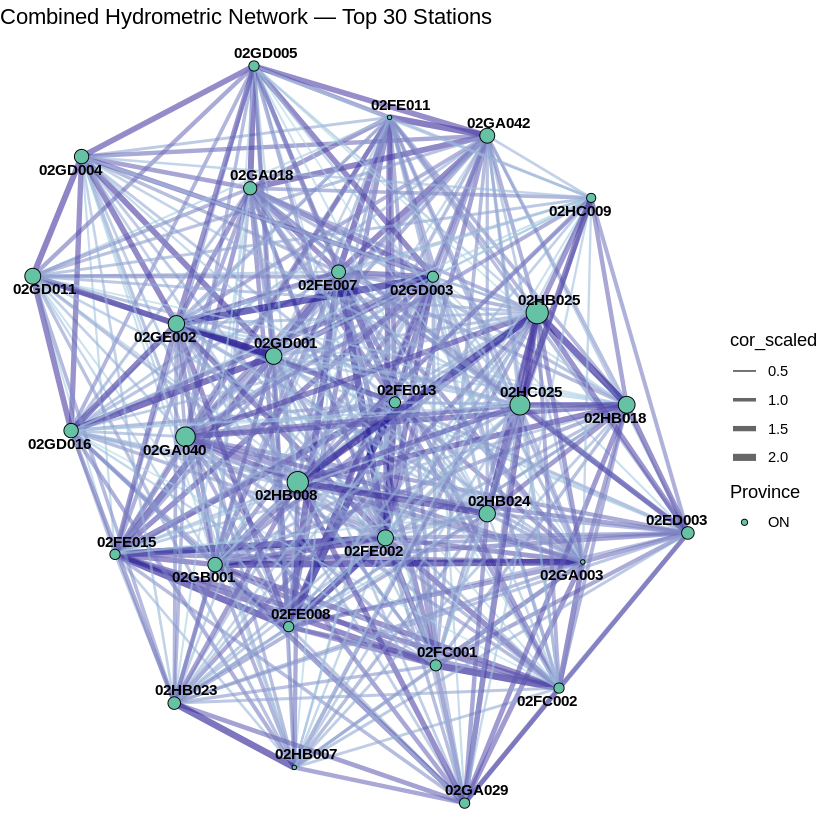

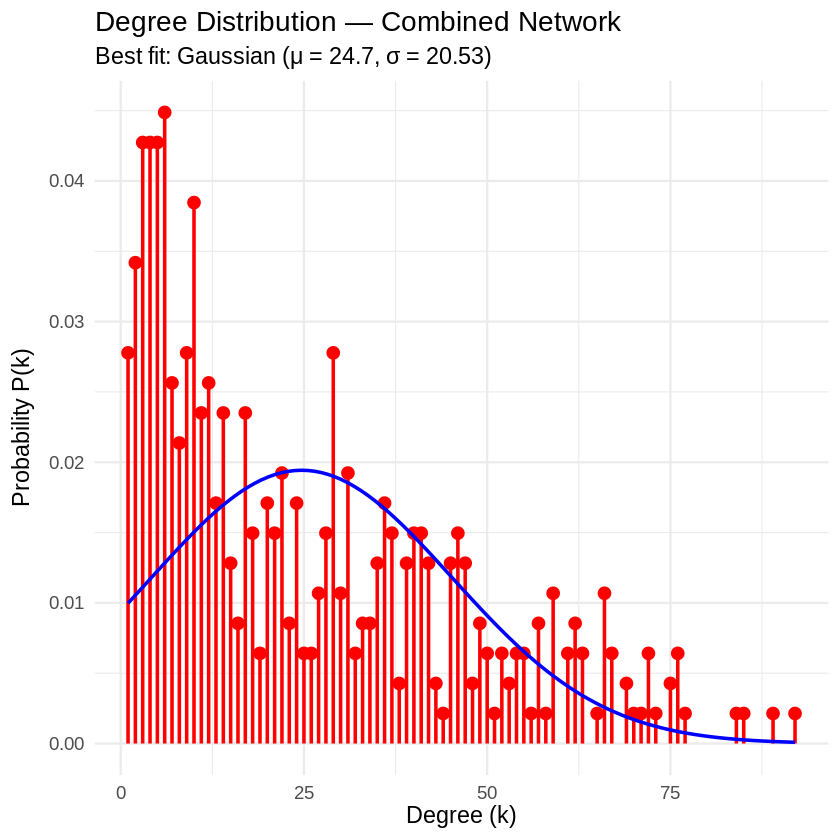

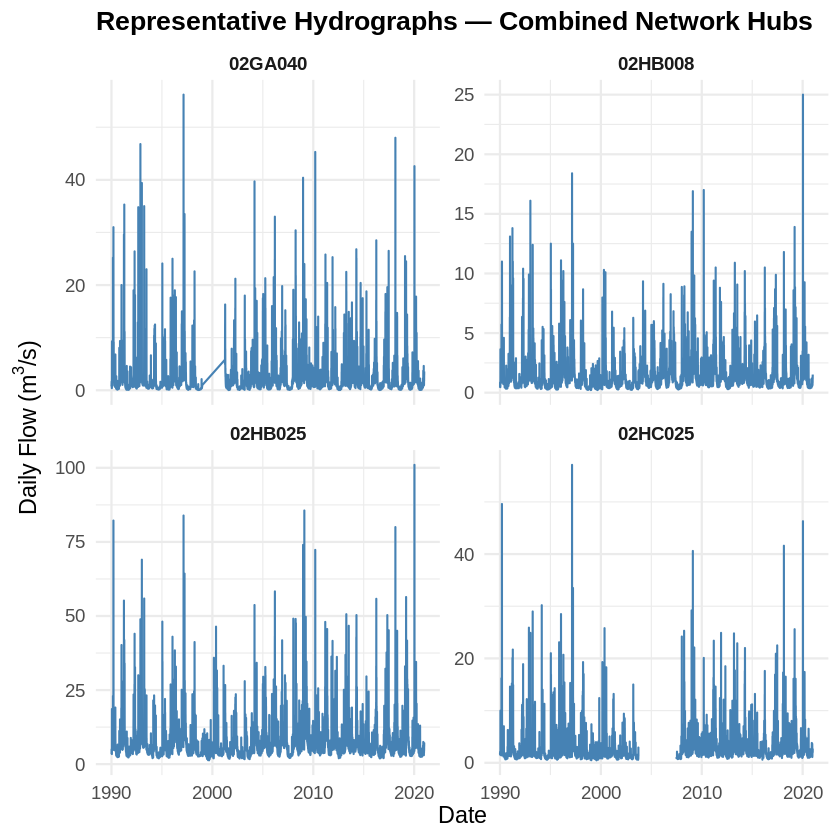

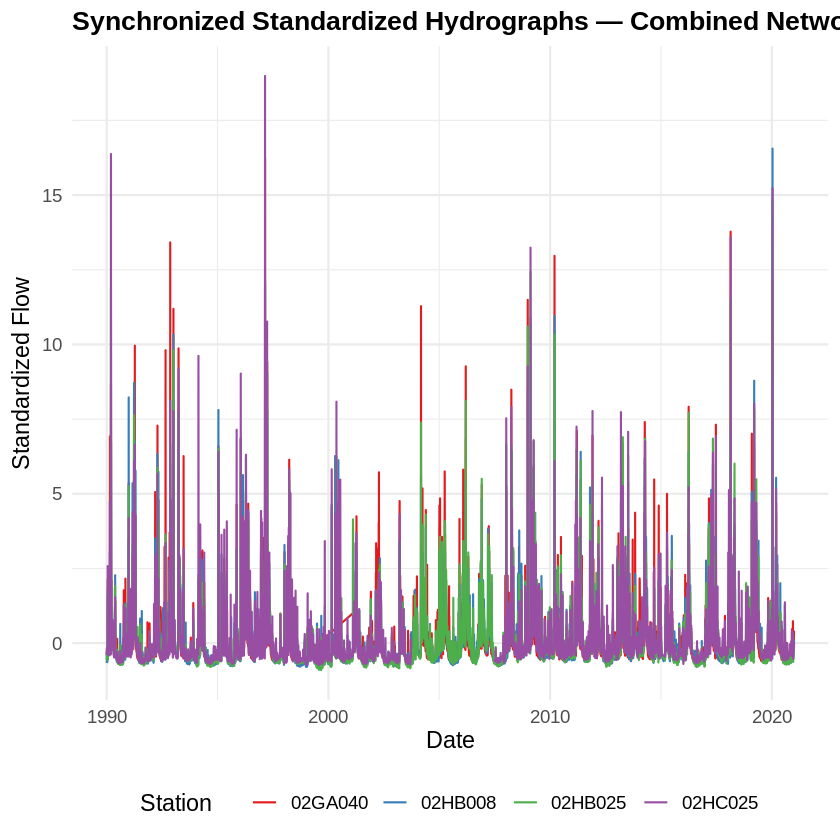

# A tibble: 47 × 6
   station province degree betweenness clustering community
   <chr>   <chr>     <dbl>       <dbl>      <dbl>     <dbl>
 1 02HB025 ON           92       2166.      0.498         4
 2 02HB008 ON           89       1884.      0.507         4
 3 02HC025 ON           85       1174.      0.519         4
 4 02GA040 ON           84        776.      0.555         4
 5 02HB018 ON           77        672.      0.563         4
 6 02GD001 ON           76        744.      0.553         4
 7 02GE002 ON           76        786.      0.568         4
 8 02HB024 ON           76        520.      0.574         4
 9 02FE002 ON           75        650.      0.605         4
10 02GD011 ON           75        434.      0.500         4
# ℹ 37 more rows


Done. Outputs written to: Combined_network_outputs



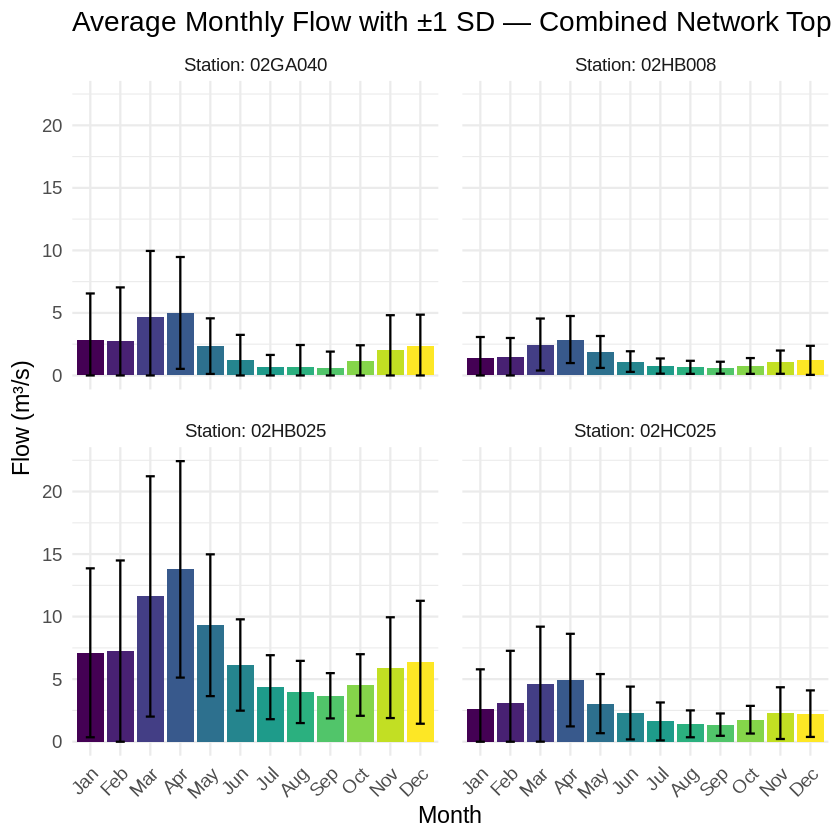

In [11]:
## =====================================================================
## 04_figures_and_exports.R
## Depends on: 00_setup.R, 01_load_data.R, 02_build_edges.R,
##             03_graph_and_metrics.R (all auto-sourced if needed)
## Produces:   all figures + CSV exports, written to RESULTS_DIR
##
## This is the stage you'll re-run most often (tweaking colors, labels,
## which stations to highlight, etc.), which is exactly why 01-03 are
## split out and cached separately -- none of that work needs to be
## redone just to change a plot.
## =====================================================================

if (!exists("USE_DRIVE_CACHE")) {
  message("00_setup.R hasn't been run yet in this session — sourcing it now...")
  source("00_setup.R")
}

if (!exists("g_giant") || !exists("node_metrics_all")) {
  message("Graph/metrics not in memory — running 03_graph_and_metrics.R ",
          "(will load from cache if available, otherwise rebuild)...")
  source("03_graph_and_metrics.R")
}

if (!exists("flow_all")) {
  cached_data_file <- cache_path("stations_flow_all.rds")
  stopifnot(file.exists(cached_data_file))
  flow_all <- readRDS(cached_data_file)$flow_all
}

if (!exists("edges_df_all")) {
  # Needed for the final CSV export below. Stage 3's cached-load branch
  # doesn't touch edges_df_all (it loads the already-built graph directly),
  # so this can be missing even when g_giant/node_metrics_all are present.
  cached_edges_file <- cache_path("edges_df_all.rds")
  stopifnot(file.exists(cached_edges_file))
  edges_df_all <- readRDS(cached_edges_file)
}

# =========================================================================
# Network visualization — top N stations by degree, coloured by province
# =========================================================================

top_n <- 30
top_nodes <- node_metrics_all %>% arrange(desc(degree)) %>% slice(1:top_n) %>% pull(station)
sub_g <- induced_subgraph(g_giant, vids = top_nodes)

E(sub_g)$cor_scaled  <- rescale(E(sub_g)$correlation, to = c(0.5, 2))
V(sub_g)$size_scaled <- rescale(V(sub_g)$degree, to = c(4, 10))

p_network <- ggraph(sub_g, layout = "fr") +
  geom_edge_link(aes(width = cor_scaled, color = correlation), alpha = 0.6) +
  scale_edge_color_gradient(low = "lightblue", high = "darkblue") +
  geom_node_point(aes(size = size_scaled, shape = PROVINCE, fill = PROVINCE),
                  color = "black", stroke = 0.4) +
  scale_shape_manual(values = c(ON = 21, QC = 22, MB = 24)) +
  scale_fill_brewer(palette = "Set2") +
  geom_node_text(aes(label = name), repel = TRUE, fontface = "bold", size = 3.2) +
  ggtitle(paste0("Combined Hydrometric Network — Top ", top_n, " Stations")) +
  theme_void() +
  guides(edge_color = guide_colorbar(title = "Correlation"),
         size = "none",
         shape = guide_legend(title = "Province"),
         fill  = guide_legend(title = "Province")) +
  scale_edge_width(range = c(0.5, 2))

print(p_network)
ggsave(result_path("Combined_network_top30.svg"), p_network, width = 10, height = 9)

# =========================================================================
# Degree distribution & Gaussian/Poisson fit
# =========================================================================

degree_vals <- node_metrics_all$degree

degree_df <- tibble(k = degree_vals) %>%
  count(k, name = "n") %>%
  mutate(Pk = n / sum(n))

fit_norm <- fitdist(degree_vals, "norm")
fit_pois <- fitdist(degree_vals, "pois")

model_comparison <- tibble(
  Model = c("Gaussian", "Poisson"),
  AIC   = c(AIC(fit_norm), AIC(fit_pois)),
  BIC   = c(BIC(fit_norm), BIC(fit_pois))
)
print(model_comparison)

best_model <- if (AIC(fit_norm) < AIC(fit_pois)) "Gaussian" else "Poisson"
mu     <- unname(fit_norm$estimate["mean"])
sigma  <- unname(fit_norm$estimate["sd"])
lambda <- unname(fit_pois$estimate["lambda"])

p_degree <- ggplot(degree_df, aes(x = k, y = Pk)) +
  geom_segment(aes(xend = k, y = 0, yend = Pk), color = "red", linewidth = 1) +
  geom_point(color = "red", size = 3) +
  theme_minimal(base_size = 14) +
  labs(title = "Degree Distribution \u2014 Combined Network",
       x = "Degree (k)", y = "Probability P(k)")

if (best_model == "Gaussian") {
  p_degree <- p_degree +
    stat_function(fun = function(x) dnorm(x, mean = mu, sd = sigma),
                  color = "blue", linewidth = 1) +
    labs(subtitle = paste0("Best fit: Gaussian (\u03bc = ", round(mu, 2),
                            ", \u03c3 = ", round(sigma, 2), ")"))
} else {
  p_degree <- p_degree +
    stat_function(fun = function(x) dpois(x, lambda = lambda),
                  color = "blue", linewidth = 1) +
    labs(subtitle = paste0("Best fit: Poisson (\u03bb = ", round(lambda, 2), ")"))
}

print(p_degree)
ggsave(result_path("Combined_degree_distribution.svg"), p_degree, width = 8, height = 5)

# =========================================================================
# Representative hydrographs — top 4 hubs (combined network)
# =========================================================================

hub_stations_all <- node_metrics_all %>%
  filter(hub) %>%
  arrange(desc(degree)) %>%
  slice(1:4) %>%
  pull(station)

hub_flows_all <- flow_all %>% filter(STATION_NUMBER %in% hub_stations_all)

p_hydrographs <- ggplot(hub_flows_all, aes(x = Date, y = Value)) +
  geom_line(color = "steelblue", linewidth = 0.6) +
  facet_wrap(~ STATION_NUMBER, ncol = 2, scales = "free_y") +
  labs(title = "Representative Hydrographs \u2014 Combined Network Hubs",
       x = "Date", y = expression("Daily Flow (m"^3*"/s)")) +
  theme_minimal(base_size = 14) +
  theme(plot.title = element_text(face = "bold", size = 16),
        strip.text = element_text(face = "bold"))

print(p_hydrographs)
ggsave(result_path("Combined_hub_hydrographs_2x2.png"), p_hydrographs, width = 12, height = 8)

hub_flows_std_all <- hub_flows_all %>%
  group_by(STATION_NUMBER) %>%
  mutate(flow_std = (Value - mean(Value, na.rm = TRUE)) / sd(Value, na.rm = TRUE)) %>%
  ungroup()

p_std <- ggplot(hub_flows_std_all, aes(x = Date, y = flow_std, color = STATION_NUMBER)) +
  geom_line(linewidth = 0.6) +
  labs(title = "Synchronized Standardized Hydrographs \u2014 Combined Network Hubs",
       x = "Date", y = "Standardized Flow", color = "Station") +
  scale_color_brewer(palette = "Set1") +
  theme_minimal(base_size = 14) +
  theme(plot.title = element_text(face = "bold", size = 16), legend.position = "bottom")

print(p_std)
ggsave(result_path("Combined_hub_hydrographs_standardized.svg"), p_std, width = 12, height = 6)

# =========================================================================
# Average monthly flow (+/- 1 SD) — top 4 hubs (combined network)
# =========================================================================

monthly_stats_top4_all <- hub_flows_all %>%
  mutate(Month = month(Date, label = TRUE, abbr = TRUE)) %>%
  group_by(STATION_NUMBER, Month) %>%
  summarise(AvgFlow = mean(Value, na.rm = TRUE),
            SDFlow  = sd(Value, na.rm = TRUE),
            .groups = "drop")

p_monthly_sd <- ggplot(monthly_stats_top4_all, aes(x = Month, y = AvgFlow, fill = Month)) +
  geom_col(show.legend = FALSE) +
  geom_errorbar(aes(ymin = pmax(AvgFlow - SDFlow, 0), ymax = AvgFlow + SDFlow),
                width = 0.3, color = "black") +
  facet_wrap(~ STATION_NUMBER, ncol = 2,
             labeller = labeller(STATION_NUMBER = function(x) paste("Station:", x))) +
  scale_fill_viridis_d() +
  theme_minimal(base_size = 14) +
  labs(title = "Average Monthly Flow with \u00b11 SD \u2014 Combined Network Top 4 Hubs",
       x = "Month", y = "Flow (m\u00b3/s)") +
  theme(panel.spacing = unit(1, "lines"),
        axis.text.x = element_text(angle = 45, hjust = 1))

print(p_monthly_sd)
ggsave(result_path("Combined_monthlySD.svg"), p_monthly_sd, width = 10, height = 7)

# =========================================================================
# Hub table (mirrors Tables 2-4 in the manuscript)
# =========================================================================

hub_table_all <- node_metrics_all %>%
  filter(hub) %>%
  arrange(desc(degree)) %>%
  dplyr::select(station, province, degree, betweenness, clustering, community)

print(hub_table_all)

# =========================================================================
# Export CSVs
# =========================================================================

write.csv(node_metrics_all,       result_path("Combined_node_metrics.csv"),           row.names = FALSE)
write.csv(hub_table_all,          result_path("Combined_hub_table.csv"),              row.names = FALSE)
write.csv(community_sizes_all,    result_path("Combined_community_sizes.csv"),        row.names = FALSE)
write.csv(community_province_mix, result_path("Combined_community_province_mix.csv"), row.names = FALSE)
write.csv(edges_df_all,           result_path("Combined_edges.csv"),                  row.names = FALSE)
write.csv(global_metrics_all,     result_path("Combined_global_metrics.csv"),         row.names = FALSE)
write.csv(component_sizes,        result_path("Combined_component_sizes.csv"),        row.names = FALSE)

message("Done. Outputs written to: ", RESULTS_DIR)


--- Recomputed provincial network summary (compare against your manuscript) ---
  province n_stations_total n_stations_giant n_components total_edges
1       ON              273              264            8        4069
2       QC              109              102            8        1041
3       MB              136               99           11         292
     density avg_degree max_degree avg_clustering avg_path_length
1 0.11720820   30.82576         92      0.6287995        4.054010
2 0.20209668   20.41176         41      0.6626252        2.752087
3 0.06019377    5.89899         14      0.5247855        4.455576
  mean_correlation max_correlation
1        0.7840870       0.9922114
2        0.7898082       0.9882594
3        0.7839000       0.9967589


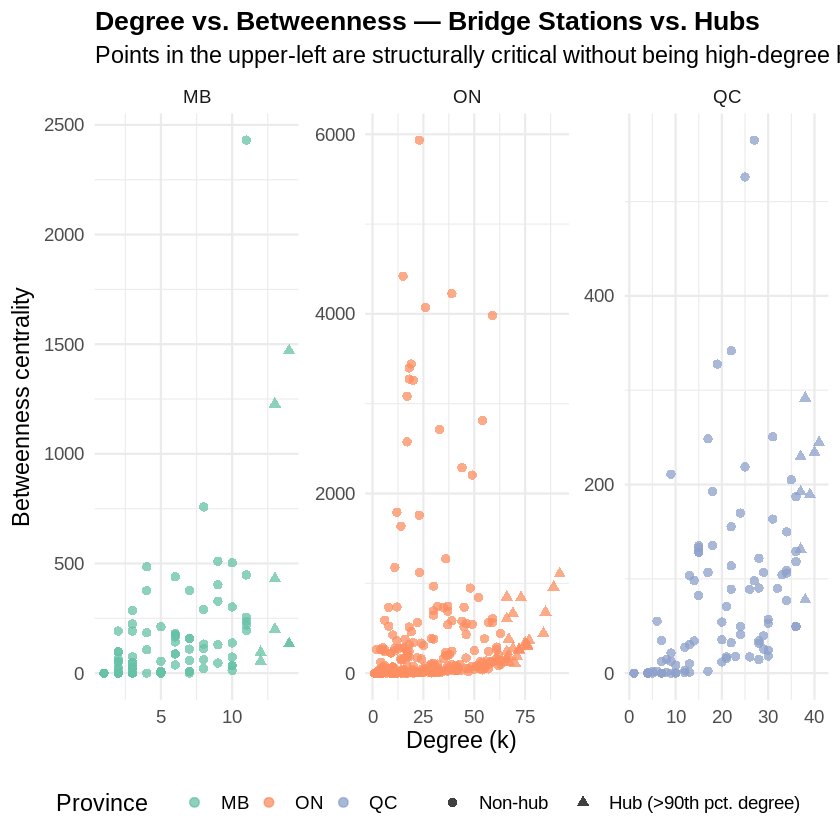

Done. Recheck table + 2 new figures written to: Combined_network_outputs



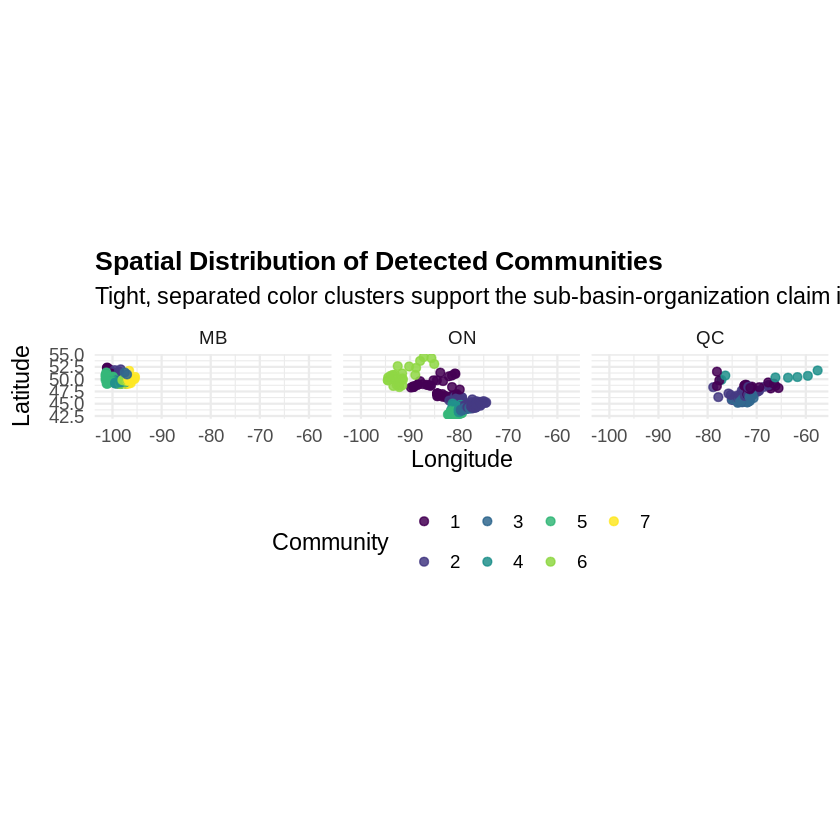

In [16]:
## =====================================================================
## 05_provincial_networks.R
## Depends on: 00_setup.R, 01_load_data.R, 02_build_edges.R (all
##             auto-sourced/loaded from cache if needed)
## Produces:   node_metrics_prov (named list, one tibble per province),
##             global_metrics_prov (one row per province)
##
## WHY THIS DOESN'T RE-DOWNLOAD OR RE-CORRELATE ANYTHING:
## edges_df_all was built from a correlation matrix over the FULL
## combined station set, but correlation between two stations is computed
## column-pairwise -- whether or not a third province's columns were also
## in that matrix doesn't change the number for any given pair. So the
## "within-province" edges already sitting in edges_df_all are numerically
## identical to what a province run on its own would produce. This script
## just filters them back apart per province, which is why it's fast
## (seconds, not minutes) even though it reconstructs the ON/QC/MB
## networks from scratch.
##
## This is a genuine independent check on the numbers already in the
## manuscript (Table 1 and the ON/QC/MB prose), since it goes through a
## different code path (built from the combined matrix, not three
## separate provincial scripts) and should land on the same values if
## everything is consistent.
## =====================================================================

if (!exists("USE_DRIVE_CACHE")) {
  message("00_setup.R hasn't been run yet in this session — sourcing it now...")
  source("00_setup.R")
}

if (!exists("edges_df_all")) {
  cached_edges_file <- cache_path("edges_df_all.rds")
  if (file.exists(cached_edges_file)) {
    edges_df_all <- readRDS(cached_edges_file)
  } else {
    source("02_build_edges.R")
  }
}

if (!exists("stations_all")) {
  cached_data_file <- cache_path("stations_flow_all.rds")
  stopifnot(file.exists(cached_data_file))
  stations_all <- readRDS(cached_data_file)$stations_all
}

# =========================================================================
# Rebuild each province's network from the within-province subset of the
# already-computed combined edge list
# =========================================================================

build_provincial_network <- function(prov_code) {

  edges_prov <- edges_df_all %>%
    filter(edge_type == "within-province", province1 == prov_code)

  stations_prov <- stations_all %>% filter(PROVINCE == prov_code)

  g_prov <- graph_from_data_frame(
    edges_prov %>% dplyr::select(station1, station2, correlation),
    directed = FALSE,
    vertices = stations_prov %>% dplyr::select(STATION_NUMBER) %>% distinct()
  )

  comp <- components(g_prov)
  giant_nodes <- V(g_prov)[comp$membership == which.max(comp$csize)]
  g_prov_giant <- induced_subgraph(g_prov, giant_nodes)

  node_metrics <- tibble(
    station     = V(g_prov_giant)$name,
    degree      = degree(g_prov_giant),
    betweenness = betweenness(g_prov_giant, weights = NA),
    clustering  = transitivity(g_prov_giant, type = "local", vids = V(g_prov_giant)),
    hub         = degree(g_prov_giant) > quantile(degree(g_prov_giant), 0.9)
  )
  node_metrics$community <- cluster_louvain(g_prov_giant, weights = NA)$membership

  V(g_prov_giant)$degree    <- node_metrics$degree
  V(g_prov_giant)$community <- node_metrics$community

  global_metrics <- tibble(
    province           = prov_code,
    n_stations_total   = vcount(g_prov),
    n_stations_giant   = vcount(g_prov_giant),
    n_components       = comp$no,
    total_edges        = ecount(g_prov_giant),
    density            = edge_density(g_prov_giant),
    avg_degree         = mean(node_metrics$degree),
    max_degree         = max(node_metrics$degree),
    avg_clustering     = transitivity(g_prov_giant, type = "global"),
    avg_path_length    = mean_distance(g_prov_giant),
    mean_correlation   = mean(edges_prov$correlation),
    max_correlation    = max(edges_prov$correlation)
  )

  list(graph = g_prov_giant, node_metrics = node_metrics, global_metrics = global_metrics)
}

provincial <- lapply(c("ON", "QC", "MB"), build_provincial_network)
names(provincial) <- c("ON", "QC", "MB")

node_metrics_prov   <- lapply(provincial, `[[`, "node_metrics")
global_metrics_prov <- bind_rows(lapply(provincial, `[[`, "global_metrics"))

cat("\n--- Recomputed provincial network summary (compare against your manuscript) ---\n")
print(as.data.frame(global_metrics_prov))

write.csv(global_metrics_prov, result_path("Provincial_recheck_global_metrics.csv"), row.names = FALSE)

# =========================================================================
# NEW FIGURE 1: Degree vs. betweenness, all three provinces
# -------------------------------------------------------------------------
# Your Manitoba prose already makes this exact distinction in words --
# "degree and betweenness centrality identify different classes of
# critical stations... 05LL002 [is] a station of intermediate degree
# that does not qualify as a hub [but has] the highest betweenness value
# in the network" -- this plot makes that argument visible instead of
# only readable. Points in the upper-left (high betweenness, modest
# degree) are bridge stations; points in the lower-right (high degree,
# modest betweenness) are locally-redundant hubs.
# =========================================================================

node_metrics_labeled <- bind_rows(
  lapply(names(node_metrics_prov), function(p) node_metrics_prov[[p]] %>% mutate(province = p))
)

p_degree_betweenness <- ggplot(node_metrics_labeled,
                                aes(x = degree, y = betweenness, color = province)) +
  geom_point(aes(shape = hub), size = 2.2, alpha = 0.75) +
  scale_shape_manual(values = c(`TRUE` = 17, `FALSE` = 16),
                      labels = c(`TRUE` = "Hub (>90th pct. degree)", `FALSE` = "Non-hub"),
                      name = NULL) +
  scale_color_brewer(palette = "Set2", name = "Province") +
  facet_wrap(~ province, scales = "free") +
  theme_minimal(base_size = 14) +
  labs(title = "Degree vs. Betweenness — Bridge Stations vs. Hubs",
       subtitle = "Points in the upper-left are structurally critical without being high-degree hubs",
       x = "Degree (k)", y = "Betweenness centrality") +
  theme(plot.title = element_text(face = "bold", size = 16),
        legend.position = "bottom")

print(p_degree_betweenness)
ggsave(result_path("Provincial_degree_vs_betweenness.svg"), p_degree_betweenness, width = 12, height = 5)

# =========================================================================
# NEW FIGURE 2: Spatial map of Louvain communities
# -------------------------------------------------------------------------
# Your Manitoba/Quebec/Ontario prose all make a spatial claim -- that
# Louvain communities "mirror the Water Survey of Canada sub-basin
# structure" / are organized by drainage geography. This is currently
# asserted from station ID prefixes (05M vs 05O, etc.) rather than shown.
# Plotting actual station coordinates, colored by detected community,
# is a direct visual test of that claim -- if it's right, communities
# should form clearly separated spatial clusters, not a scatter of
# interleaved colors.
# =========================================================================

coords_by_prov <- lapply(names(node_metrics_prov), function(p) {
  node_metrics_prov[[p]] %>%
    left_join(stations_all %>% filter(PROVINCE == p) %>%
                dplyr::select(STATION_NUMBER, LATITUDE, LONGITUDE),
              by = c("station" = "STATION_NUMBER")) %>%
    mutate(province = p)
}) %>% bind_rows() %>%
  filter(!is.na(LATITUDE), !is.na(LONGITUDE))

p_community_map <- ggplot(coords_by_prov,
                           aes(x = LONGITUDE, y = LATITUDE, color = factor(community))) +
  geom_point(size = 2, alpha = 0.85) +
  facet_wrap(~ province) + # Removed scales = "free" due to conflict with coord_fixed()
  coord_fixed() +
  scale_color_viridis_d(name = "Community") +
  theme_minimal(base_size = 14) +
  labs(title = "Spatial Distribution of Detected Communities",
       subtitle = "Tight, separated color clusters support the sub-basin-organization claim in the text",
       x = "Longitude", y = "Latitude") +
  theme(plot.title = element_text(face = "bold", size = 16),
        legend.position = "bottom")

print(p_community_map)
ggsave(result_path("Provincial_community_map.svg"), p_community_map, width = 16, height = 9)

message("Done. Recheck table + 2 new figures written to: ", RESULTS_DIR)


--- Recomputed provincial network summary (compare against your manuscript) ---
  province n_stations_total n_stations_giant n_components total_edges
1       ON              273              264            8        4069
2       QC              109              102            8        1041
3       MB              136               99           11         292
     density avg_degree max_degree avg_clustering avg_path_length
1 0.11720820   30.82576         92      0.6287995        4.054010
2 0.20209668   20.41176         41      0.6626252        2.752087
3 0.06019377    5.89899         14      0.5247855        4.455576
  mean_correlation max_correlation
1        0.7840870       0.9922114
2        0.7898082       0.9882594
3        0.7839000       0.9967589


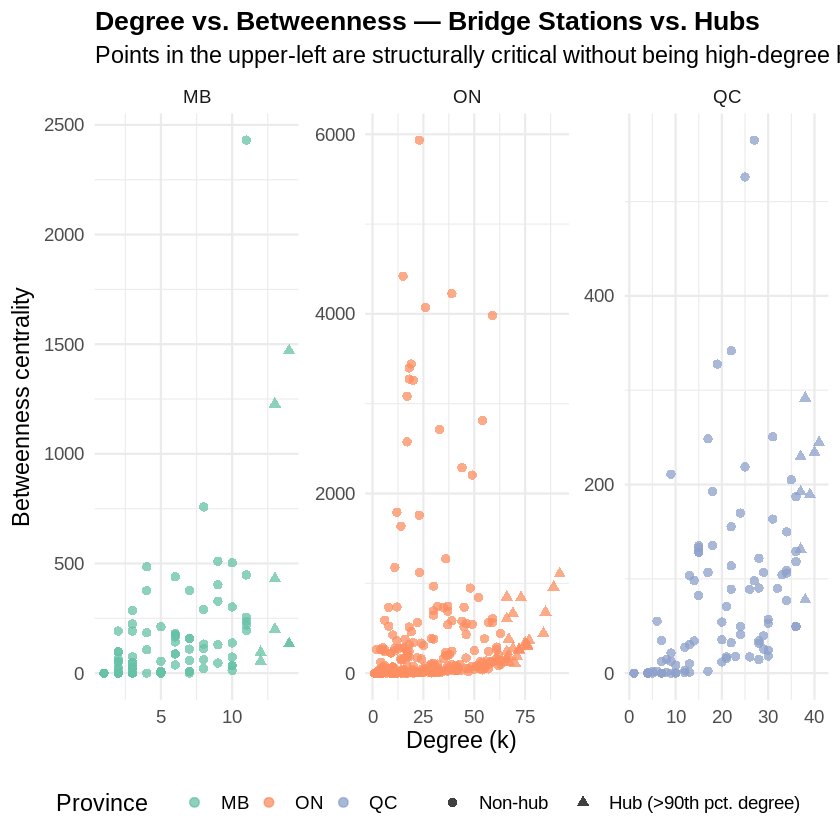

Done. Recheck table + 2 new figures written to: Combined_network_outputs



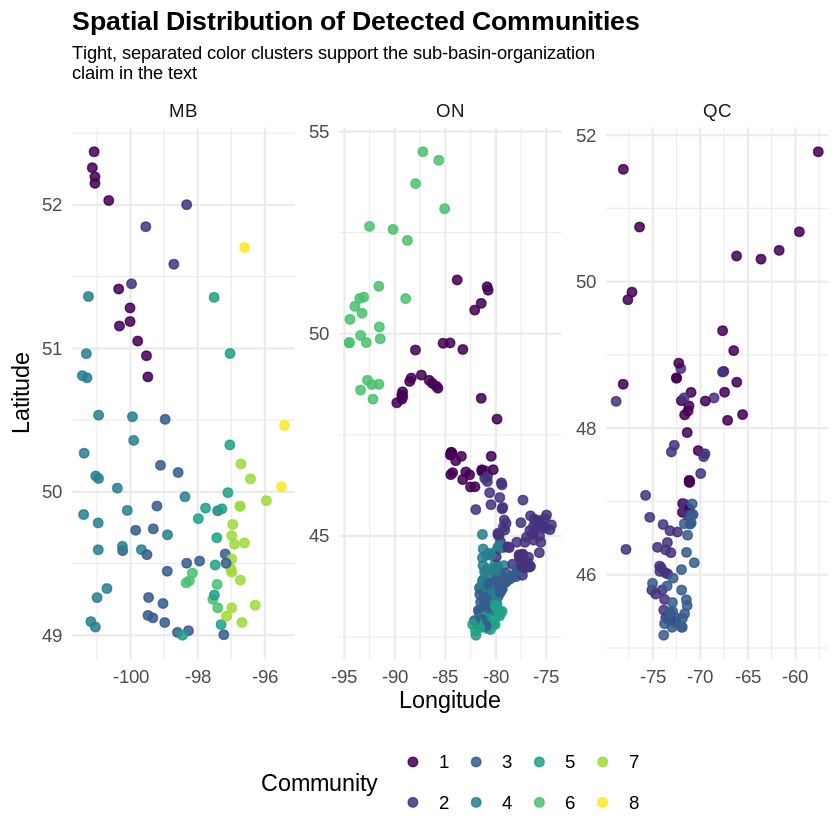

In [17]:
## =====================================================================
## 05_provincial_networks.R
## Depends on: 00_setup.R, 01_load_data.R, 02_build_edges.R (all
##             auto-sourced/loaded from cache if needed)
## Produces:   node_metrics_prov (named list, one tibble per province),
##             global_metrics_prov (one row per province)
##
## WHY THIS DOESN'T RE-DOWNLOAD OR RE-CORRELATE ANYTHING:
## edges_df_all was built from a correlation matrix over the FULL
## combined station set, but correlation between two stations is computed
## column-pairwise -- whether or not a third province's columns were also
## in that matrix doesn't change the number for any given pair. So the
## "within-province" edges already sitting in edges_df_all are numerically
## identical to what a province run on its own would produce. This script
## just filters them back apart per province, which is why it's fast
## (seconds, not minutes) even though it reconstructs the ON/QC/MB
## networks from scratch.
##
## This is a genuine independent check on the numbers already in the
## manuscript (Table 1 and the ON/QC/MB prose), since it goes through a
## different code path (built from the combined matrix, not three
## separate provincial scripts) and should land on the same values if
## everything is consistent.
## =====================================================================

if (!exists("USE_DRIVE_CACHE")) {
  message("00_setup.R hasn't been run yet in this session — sourcing it now...")
  source("00_setup.R")
}

if (!exists("edges_df_all")) {
  cached_edges_file <- cache_path("edges_df_all.rds")
  if (file.exists(cached_edges_file)) {
    edges_df_all <- readRDS(cached_edges_file)
  } else {
    source("02_build_edges.R")
  }
}

if (!exists("stations_all")) {
  cached_data_file <- cache_path("stations_flow_all.rds")
  stopifnot(file.exists(cached_data_file))
  stations_all <- readRDS(cached_data_file)$stations_all
}

# =========================================================================
# Rebuild each province's network from the within-province subset of the
# already-computed combined edge list
# =========================================================================

build_provincial_network <- function(prov_code) {

  edges_prov <- edges_df_all %>%
    filter(edge_type == "within-province", province1 == prov_code)

  stations_prov <- stations_all %>% filter(PROVINCE == prov_code)

  g_prov <- graph_from_data_frame(
    edges_prov %>% dplyr::select(station1, station2, correlation),
    directed = FALSE,
    vertices = stations_prov %>% dplyr::select(STATION_NUMBER) %>% distinct()
  )

  comp <- components(g_prov)
  giant_nodes <- V(g_prov)[comp$membership == which.max(comp$csize)]
  g_prov_giant <- induced_subgraph(g_prov, giant_nodes)

  node_metrics <- tibble(
    station     = V(g_prov_giant)$name,
    degree      = degree(g_prov_giant),
    betweenness = betweenness(g_prov_giant, weights = NA),
    clustering  = transitivity(g_prov_giant, type = "local", vids = V(g_prov_giant)),
    hub         = degree(g_prov_giant) > quantile(degree(g_prov_giant), 0.9)
  )
  node_metrics$community <- cluster_louvain(g_prov_giant, weights = NA)$membership

  V(g_prov_giant)$degree    <- node_metrics$degree
  V(g_prov_giant)$community <- node_metrics$community

  global_metrics <- tibble(
    province           = prov_code,
    n_stations_total   = vcount(g_prov),
    n_stations_giant   = vcount(g_prov_giant),
    n_components       = comp$no,
    total_edges        = ecount(g_prov_giant),
    density            = edge_density(g_prov_giant),
    avg_degree         = mean(node_metrics$degree),
    max_degree         = max(node_metrics$degree),
    avg_clustering     = transitivity(g_prov_giant, type = "global"),
    avg_path_length    = mean_distance(g_prov_giant),
    mean_correlation   = mean(edges_prov$correlation),
    max_correlation    = max(edges_prov$correlation)
  )

  list(graph = g_prov_giant, node_metrics = node_metrics, global_metrics = global_metrics)
}

provincial <- lapply(c("ON", "QC", "MB"), build_provincial_network)
names(provincial) <- c("ON", "QC", "MB")

node_metrics_prov   <- lapply(provincial, `[[`, "node_metrics")
global_metrics_prov <- bind_rows(lapply(provincial, `[[`, "global_metrics"))

cat("\n--- Recomputed provincial network summary (compare against your manuscript) ---\n")
print(as.data.frame(global_metrics_prov))

write.csv(global_metrics_prov, result_path("Provincial_recheck_global_metrics.csv"), row.names = FALSE)

# =========================================================================
# NEW FIGURE 1: Degree vs. betweenness, all three provinces
# -------------------------------------------------------------------------
# Your Manitoba prose already makes this exact distinction in words --
# "degree and betweenness centrality identify different classes of
# critical stations... 05LL002 [is] a station of intermediate degree
# that does not qualify as a hub [but has] the highest betweenness value
# in the network" -- this plot makes that argument visible instead of
# only readable. Points in the upper-left (high betweenness, modest
# degree) are bridge stations; points in the lower-right (high degree,
# modest betweenness) are locally-redundant hubs.
# =========================================================================

node_metrics_labeled <- bind_rows(
  lapply(names(node_metrics_prov), function(p) node_metrics_prov[[p]] %>% mutate(province = p))
)

p_degree_betweenness <- ggplot(node_metrics_labeled,
                                aes(x = degree, y = betweenness, color = province)) +
  geom_point(aes(shape = hub), size = 2.2, alpha = 0.75) +
  scale_shape_manual(values = c(`TRUE` = 17, `FALSE` = 16),
                      labels = c(`TRUE` = "Hub (>90th pct. degree)", `FALSE` = "Non-hub"),
                      name = NULL) +
  scale_color_brewer(palette = "Set2", name = "Province") +
  facet_wrap(~ province, scales = "free") +
  theme_minimal(base_size = 14) +
  labs(title = "Degree vs. Betweenness \u2014 Bridge Stations vs. Hubs",
       subtitle = "Points in the upper-left are structurally critical without being high-degree hubs",
       x = "Degree (k)", y = "Betweenness centrality") +
  theme(plot.title = element_text(face = "bold", size = 16),
        legend.position = "bottom")

print(p_degree_betweenness)
ggsave(result_path("Provincial_degree_vs_betweenness.svg"), p_degree_betweenness, width = 12, height = 5)

# =========================================================================
# NEW FIGURE 2: Spatial map of Louvain communities
# -------------------------------------------------------------------------
# Your Manitoba/Quebec/Ontario prose all make a spatial claim -- that
# Louvain communities "mirror the Water Survey of Canada sub-basin
# structure" / are organized by drainage geography. This is currently
# asserted from station ID prefixes (05M vs 05O, etc.) rather than shown.
# Plotting actual station coordinates, colored by detected community,
# is a direct visual test of that claim -- if it's right, communities
# should form clearly separated spatial clusters, not a scatter of
# interleaved colors.
# =========================================================================

coords_by_prov <- lapply(names(node_metrics_prov), function(p) {
  node_metrics_prov[[p]] %>%
    left_join(stations_all %>% filter(PROVINCE == p) %>%
                dplyr::select(STATION_NUMBER, LATITUDE, LONGITUDE),
              by = c("station" = "STATION_NUMBER")) %>%
    mutate(province = p)
}) %>% bind_rows() %>%
  filter(!is.na(LATITUDE), !is.na(LONGITUDE))

p_community_map <- ggplot(coords_by_prov,
                           aes(x = LONGITUDE, y = LATITUDE, color = factor(community))) +
  geom_point(size = 2.2, alpha = 0.85) +
  facet_wrap(~ province, scales = "free") +
  scale_x_continuous(breaks = scales::pretty_breaks(n = 4)) +
  scale_y_continuous(breaks = scales::pretty_breaks(n = 4)) +
  scale_color_viridis_d(name = "Community") +
  theme_minimal(base_size = 14) +
  labs(title = "Spatial Distribution of Detected Communities",
       subtitle = stringr::str_wrap(
         "Tight, separated color clusters support the sub-basin-organization claim in the text",
         width = 70),
       x = "Longitude", y = "Latitude") +
  theme(plot.title = element_text(face = "bold", size = 16),
        plot.subtitle = element_text(size = 11),
        legend.position = "bottom")

print(p_community_map)
ggsave(result_path("Provincial_community_map.svg"), p_community_map, width = 13, height = 6.5)
ggsave(result_path("Provincial_community_map.png"), p_community_map, width = 13, height = 6.5, dpi = 200)

message("Done. Recheck table + 2 new figures written to: ", RESULTS_DIR)